# E-Commerce Customer Lifecycle Segmentation and Churn Prediction




## Data Source

 [Kaggle — Online Retail II UCI Dataset](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci)




## Project Description

**Business Context**

A UK retailer sells gift items. Many of its buyers are wholesalers. Like any shop, it loses customers over time. People buy for a while, then stop. The shop wants to spot those people early and win them back.

**Data**

Sales records from December 2009 to December 2011. About 1.07 million rows. Each row is one item on one receipt; the invoice number, the product code and name, how many were bought, the date, the price, the customer's ID number, and the country. The dataset contains no website visits, no emails, no returns reasons, no demographics.


**The two things being built**

1. *RFM Segmentation:* Sort customers into groups based on how they shop. For example, buys often and spends a lot, buys rarely but spends big, used to buy but has gone quiet.

2. *A churn prediction model:* For each customer, at a chosen point in time, predict whether they will place another order in the next 90 days. The model looks only at how a person shopped before that date, so it works the same way the shop would use it in practice; like for today with no knowledge of what happens next.


##### How "churn" is defined for this project

A customer is called churned if they do not buy anything in the 90 days after a chosen cutoff date. After learning from the training, the model looks at how a person shopped before that date and guesses whether they will come back within those three months.

**Who uses it**

The customer relationship team. Instead of emailing everyone the same offer, they can rank customers by risk and spend their budget on the people most likely to matter.


In [1]:
# Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Data Prep: Importing, Cleaning and Preprocessing



In [2]:
#importing dataset

df = pd.read_csv("../data/online_retail_II.csv.gz")


df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [4]:
# Formatting the string values - removing whitespace, making lower case and replacing spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

In [5]:
# Duplicates
duplicate_rows = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_rows:,} ({duplicate_rows / len(df) * 100:.2f}% of the data)")

Exact duplicate rows: 34,335 (3.22% of the data)


In [6]:
# All duplicate rows
df[df.duplicated(keep=False)].sort_values(list(df.columns))

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
965610,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,2011-11-04 13:25:00,2.95,15110.0,United Kingdom
986868,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
986869,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,2011-11-13 11:38:00,0.55,17838.0,United Kingdom
1055441,C580764,22667,RECIPE BOX RETROSPOT,-12,2011-12-06 10:38:00,2.95,14562.0,United Kingdom


##### Why we're removing exact duplicate rows

The dataset contains a number of exact duplicate line items, where the same product, quantity, invoice number and timestamp all appear more than once. These are data entry error or artefacts than real repeat purchases. Because all these purchases can not happen with same customer id with the exact timestamp.
If we leave them in, they will inflate every monetary figure we calculate later, because the same spend gets counted twice for the same customer. Removing them here, before any grouping or aggregation, means every further calculation is built on real transactions only.

In [7]:
# Removing duplicates

df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows remaining after removing duplicates: {len(df):,}")

Rows remaining after removing duplicates: 1,033,036


### Inspecting each column

#### Column: Customer ID

In [8]:
col = 'customer_id'

print("Data type:", df[col].dtype)
print("Total rows:", len(df))
print("Distinct customers:", df[col].nunique())
print("Missing values:", df[col].isnull().sum(),
      f"({df[col].isnull().mean()*100:.2f}%)")

Data type: float64
Total rows: 1033036
Distinct customers: 5942
Missing values: 235151 (22.76%)


In [9]:
# Checking if is there any order where some lines have a customer ID and other lines in the same order are blank

per_invoice = df.groupby('invoice')['customer_id'].agg(
    n_ids='nunique',
    n_missing=lambda s: s.isnull().sum())

mixed = per_invoice[(per_invoice['n_ids'] >= 1) & (per_invoice['n_missing'] > 0)]


print("Invoices with both an ID and a blank:", len(mixed))
print("Invoices with more than one customer ID:", (per_invoice['n_ids'] > 1).sum())

Invoices with both an ID and a blank: 0
Invoices with more than one customer ID: 0


In [10]:
# Revenue kept vs revenue lost if we drop rows with no Customer ID
df['revenue'] = df['quantity'] * df['price']

known = df['customer_id'].notnull()

total_revenue = df['revenue'].sum()
known_revenue = df.loc[known, 'revenue'].sum()

print(f"Rows with a known customer: {known.sum():,} ({known.mean()*100:.1f}%)")
print(f"Total revenue: £{total_revenue:,.2f}")
print(f"Revenue with a known customer: £{known_revenue:,.2f}")
print(f"Share of revenue retained: {known_revenue/total_revenue*100:.1f}%")

Rows with a known customer: 797,885 (77.2%)
Total revenue: £18,855,533.70
Revenue with a known customer: £16,289,991.29
Share of revenue retained: 86.4%


**Why we should drop the missing ones**
This code checks whether any missing Customer ID can be recovered by looking at other rows in the same transaction record. It groups the data by invoice, then for each order counts how many different customer IDs appear in it and how many rows are blank. From that, it checks two things, one, are there orders that are partly filled in (some rows have an ID, others in the same order don't). And are there orders with more than one customer attached.

Since both are zero, every order is either fully identified or fully blank, never a mix. That means there's no customer ID anywhere nearby to copy over these empty cells, so the missing Customer IDs can't be recovered from the data, they have to be dropped.

The shop never captured who made these purchases, most likely guest checkouts or unregistered sales. Since our analysis identifying and segmenting customers based on this sakes data and our model needs to attach behaviour to a specific person, a row with no person attached can't be used, and there's no realistic way to invent one. So the only responsible option is to drop them before building the customer-level table, and the analysis only covers customers the shop identified (roughly 77% of rows, and around 86% of revenue).

In [11]:
# Dropping rows with empty customer_id and converting the column to string datatype

df = df.dropna(subset=['customer_id']).reset_index(drop=True)
df['customer_id'] = df['customer_id'].astype(int).astype(str)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 797885 entries, 0 to 797884
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   invoice      797885 non-null  str    
 1   stockcode    797885 non-null  str    
 2   description  797885 non-null  str    
 3   quantity     797885 non-null  int64  
 4   invoicedate  797885 non-null  str    
 5   price        797885 non-null  float64
 6   customer_id  797885 non-null  str    
 7   country      797885 non-null  str    
 8   revenue      797885 non-null  float64
dtypes: float64(2), int64(1), str(6)
memory usage: 112.4 MB


There is no more missing values in any of the column.

### Column: Invoice Date

In [13]:
# Convert to a real datetime dtype, and rename the column
df['invoicedate'] = pd.to_datetime(df['invoicedate'])
df = df.rename(columns={'invoicedate': 'invoice_date'})

print(df['invoice_date'].dtype)
df['invoice_date'].head()

datetime64[us]


0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
Name: invoice_date, dtype: datetime64[us]

In [14]:
print("Earliest date:", df['invoice_date'].min())
print("Latest date:", df['invoice_date'].max())
print("Span (days):", (df['invoice_date'].max() - df['invoice_date'].min()).days)
df['invoice_date'].dt.day_name().value_counts()

Earliest date: 2009-12-01 07:45:00
Latest date: 2011-12-09 12:50:00
Span (days): 738


invoice_date
Thursday     160482
Tuesday      138012
Wednesday    134029
Sunday       131212
Monday       127784
Friday       105966
Saturday        400
Name: count, dtype: int64

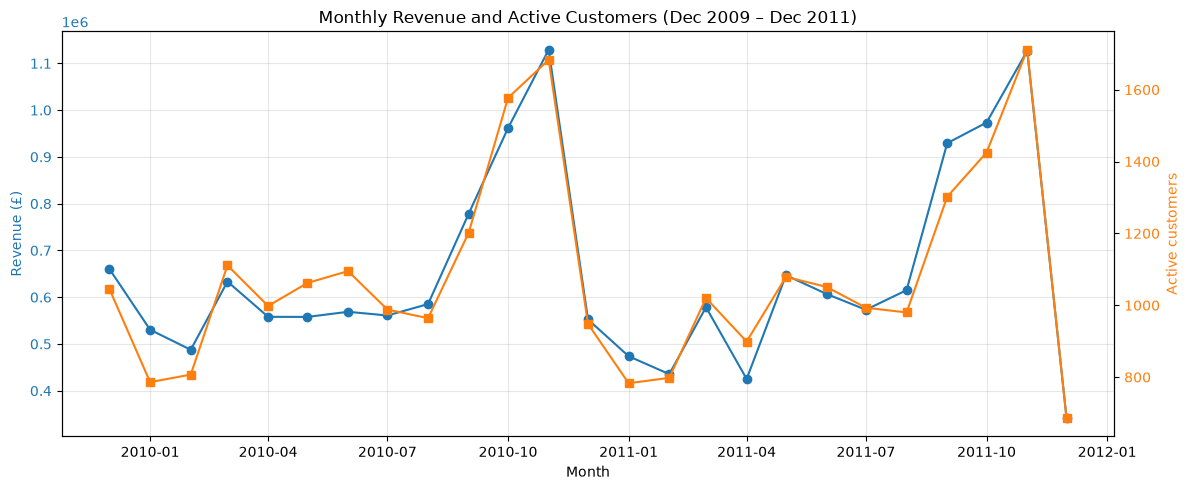

In [15]:
# Looking at monthly revenue and customer volume across the timeline

monthly_rev = df.set_index('invoice_date')['revenue'].resample('MS').sum()
monthly_cust = df.set_index('invoice_date')['customer_id'].resample('MS').nunique()

fig, ax1 = plt.subplots(figsize=(12, 5))

# Revenue on the left axis
ax1.plot(monthly_rev.index, monthly_rev.values, marker='o', color='tab:blue', label='Revenue')
ax1.set_xlabel('Month')
ax1.set_ylabel('Revenue (£)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(alpha=0.3)

# Customer count on the right axis
ax2 = ax1.twinx()
ax2.plot(monthly_cust.index, monthly_cust.values, marker='s', color='tab:orange', label='Active customers')
ax2.set_ylabel('Active customers', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('Monthly Revenue and Active Customers (Dec 2009 – Dec 2011)')
fig.tight_layout()
plt.show()

##### What the monthly revenue and customer volume chart shows

Revenue and active customer count move together almost in lockstep rhythm throughout the whole timeline. Every year, both climb sharply in October and November, peaking above £1.1 million and around 1,700 active customers in November, before dropping back down in the new year. This lines up with the run-up to Christmas, which makes sense for a gift-ware retailer.

Since the two lines rise and fall together, it looks like the November peak comes from more customers buying that month, not from existing customers each spending more.

January to August sit in a steady and in lower band, roughly £450k–£650k in revenue and 800–1,100 active customers. This is a normal seasonal dip.

December 2011 looks like a steep drop on the chart, but that's not real. The dataset only covers the first 9 days of that month, not the full month, so the low number is because the data was cut short.


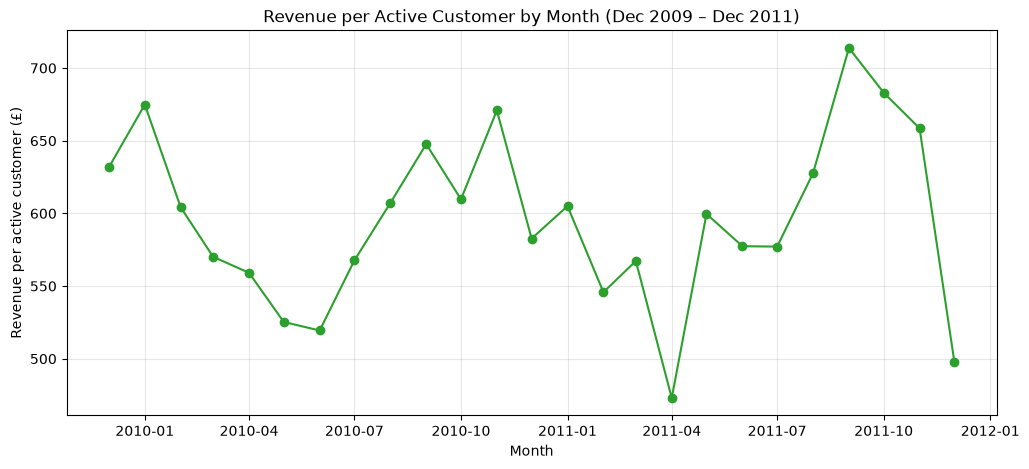

In [16]:
# Revenue per active customer each month
rev_per_cust = monthly_rev / monthly_cust

plt.figure(figsize=(12, 5))
plt.plot(rev_per_cust.index, rev_per_cust.values, marker='o', color='tab:green')
plt.title('Revenue per Active Customer by Month (Dec 2009 – Dec 2011)')
plt.xlabel('Month')
plt.ylabel('Revenue per active customer (£)')
plt.grid(alpha=0.3)
plt.show()

##### What the revenue per active customer chart shows

The line stays in a fairly narrow band, mostly between about £520 and £680 per customer per month. It rises a little in the autumn (for example £671 in November 2010 and £714 in September 2011), but far less than total revenue, which roughly doubles at the November peak. Active customers go up by about 60–70% over the same months.

**So most of the November peak comes from more customers buying that month, with a smaller part from each customer spending a bit more.** December 2011 dips again only because the month is cut short in our dataset.

### Column: Country

In [17]:
col = 'country'

print("Distinct countries:", df[col].nunique())
print()

country_summary = pd.DataFrame({
    'transactions': df[col].value_counts(),
    'pct_of_total': (df[col].value_counts(normalize=True) * 100).round(2)
})
country_summary

Distinct countries: 41



,transactions,pct_of_total
country,,
United Kingdom,716115,89.75
Germany,17339,2.17
EIRE,16014,2.01
France,13897,1.74
Netherlands,5137,0.64
Spain,3754,0.47
Belgium,3110,0.39
Switzerland,3058,0.38
Portugal,2414,0.30


In [18]:
# Converting the 'country' column into a UK / non-UK flag
df['country'] = df['country'].apply(lambda x: 'UK' if x == 'United Kingdom' else 'non-UK')

# Verifying the changes by checking the percentage of each group
print(df['country'].value_counts(normalize=True) * 100)

country
UK        89.751656
non-UK    10.248344
Name: proportion, dtype: float64


In [19]:
revenue_summary = df.groupby('country')['revenue'].agg(
    total_revenue='sum',
    average_revenue='mean'
).round(1)

print(revenue_summary)

         total_revenue  average_revenue
country                                
UK          13482505.1             18.8
non-UK       2807486.2             34.3


UK makes up 89.8% of rows but only 82.8% of revenue. The average line item from a non-UK order is worth roughly double a UK one (£34.33 vs £18.83). Non-UK buyers are fewer in number but tend to order bigger, higher-value line items each time, likely wholesalers placing larger single orders, rather than casual buyers making small individual gift purchases.

### Columns: Stockcode and Description (Product Catalog)

In [20]:
# Counting how many unique descriptions exist for each stock code
description_counts = df.groupby('stockcode')['description'].nunique()

# Filtering for only the stock codes that have more than 1 description
stockcodes_with_multiple_names = description_counts[description_counts > 1].index

# Creating a view showing the stock codes and their different names
mismatched_data = df[df['stockcode'].isin(stockcodes_with_multiple_names)][['stockcode', 'description']].drop_duplicates()

# Sorting and printing the top 20 results to examine the variations
print(mismatched_data.sort_values(by='stockcode').head(20))


       stockcode                          description
45726     15058A      BLUE WHITE SPOTS GARDEN PARASOL
411137    15058A         BLUE POLKADOT GARDEN PARASOL
45770     15058B      PINK WHITE SPOTS GARDEN PARASOL
364150    15058B         PINK POLKADOT GARDEN PARASOL
7329       16011                      ANIMAL STICKERS
87433      16011                      ANIMAL STICKERS
3182       16012           FOOD/DRINK SPUNGE STICKERS
244493     16012           FOOD/DRINK SPONGE STICKERS
136850    16151A  FLOWER DES BLUE HANDBAG/ORANG HANDL
524456    16151A      FLOWERS HANDBAG blue and orange
35225     16156L                       WRAP, CAROUSEL
489381    16156L                        WRAP CAROUSEL
1901      16161U                WRAP,SUKI AND FRIENDS
199327    16161U                WRAP SUKI AND FRIENDS
7116      17107D  FLOWER FAIRY,5 SUMMER B'DRAW LINERS
624207    17107D         FLOWER FAIRY 5 DRAWER LINERS
647726    17107D    FLOWER FAIRY 5 SUMMER DRAW LINERS
15090     17129F          DE

##### Identifying Product Description Mismatches
By isolating the stock codes with multiple names, we can see why the inconsistencies exist in our dataset. The output reveals that the mismatched descriptions are primarily due to minor data entry variations over time. These include simple typos (e.g., "SPUNGE" vs. "SPONGE"), punctuation differences (e.g., "WRAP, CAROUSEL" vs. "WRAP CAROUSEL"), and slight phrasing updates (e.g., "WHITE SPOTS" vs. "POLKADOT") for the exact same item. 

##### Next Step: Standardize the Catalog

Currently, the main dataset still contains all of these variations. To fix this and ensure accurate product analysis later we should standardize the text. We need to apply a function that finds the most frequently used description for each stock code and assigns it consistently across every row in the dataset.

In [21]:
# Find the most frequently used description for each stock code
most_common_description = df.groupby('stockcode')['description'].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA
)

# Apply that single description to every row sharing that stock code
df['description'] = df['stockcode'].map(most_common_description)

# Verify: no stock code should have more than one description now
check = df.groupby('stockcode')['description'].nunique()
print("Stock codes with more than one description remaining:", (check > 1).sum())


# Verifying it worked by checking the unique counts again
print("Unique stock codes:", df['stockcode'].nunique())
print("Unique descriptions:", df['description'].nunique())

Stock codes with more than one description remaining: 0
Unique stock codes: 4646
Unique descriptions: 4620


In [22]:
import re

def get_pattern(code):
    # Turn letters into L and digits into D, so codes collapse into shapes
    no_letters = re.sub(r'[A-Za-z]', 'L', code)
    return re.sub(r'[0-9]', 'D', no_letters)

df['code_pattern'] = df['stockcode'].apply(get_pattern)

pattern_summary = df.groupby('code_pattern')['stockcode'].agg(
    distinct_codes='nunique',
    row_count='count'
).sort_values('distinct_codes', ascending=False)

print(pattern_summary)

              distinct_codes  row_count
code_pattern                           
DDDDD                   3331     706085
DDDDDL                  1299      86995
DDDDDLL                    3       1143
LLLL                       3       2018
L                          2       1255
LLLLDDD                    2         16
LLDDDD                     1          2
LD                         1        254
LLL                        1         16
LLLL LLLLLLL               1         37
LLLLLL                     1         61
LLLLLLD                    1          3


From this observation we can tell that real product codes are 5 digits, sometimes followed by letters (e.g. 85048, 79323P). Since we are solving a problem that is for CRM teams targetting specific customers, so we will keep the rows for these standard product codes and drop the rest.

In [23]:
 #Inspecting every stockcode that does not follow the merchant's standard product format.
non_standard_codes = df.loc[~df['stockcode'].str.upper().str.match(r'^\d{5}[A-Z]*$', na=False), 'stockcode'].unique()

print(f"Number of non-standard stockcodes found: {len(non_standard_codes)}")
print(non_standard_codes)

df = df[~df['stockcode'].isin(non_standard_codes)]

# Verifying the drop by checking the new size of your dataset
print(f"Data remaining after removing non-product codes: {len(df)} rows")

Number of non-standard stockcodes found: 13
<ArrowStringArray>
[        'POST',            'D',            'M',           'C2',
 'BANK CHARGES',      'TEST001',      'TEST002',         'PADS',
       'ADJUST',      'ADJUST2',       'SP1002',          'DOT',
         'CRUK']
Length: 13, dtype: str
Data remaining after removing non-product codes: 794223 rows


In [24]:
# Verifying it worked by checking the unique counts again
print("Unique stock codes:", df['stockcode'].nunique())
print("Unique descriptions:", df['description'].nunique())

Unique stock codes: 4633
Unique descriptions: 4608


### Column: Invoice

In [25]:
col = 'invoice'

print("Data type:", df[col].dtype)
print("Distinct invoices:", df[col].nunique())
print()
print("Sample of values:")
print(df[col].drop_duplicates().head(10).tolist())

Data type: str
Distinct invoices: 43879

Sample of values:
['489434', '489435', '489436', '489437', '489438', '489439', '489440', '489441', '489442', '489443']


In [26]:
# Turning each invoice number into a shape (L = letter, D = digit)
df['invoice_pattern'] = df[col].astype(str).apply(get_pattern)

invoice_patterns = df.groupby('invoice_pattern')[col].agg(
    distinct_invoices='nunique',
    row_count='count'
).sort_values('distinct_invoices', ascending=False)

print(invoice_patterns)

                 distinct_invoices  row_count
invoice_pattern                              
DDDDDD                       36597     776637
LDDDDDD                       7282      17586


In [27]:
for pattern in invoice_patterns.index:
    sample = df.loc[df['invoice_pattern'] == pattern, col].drop_duplicates().head(5).tolist()
    print(f"{pattern}: {sample}")

DDDDDD: ['489434', '489435', '489436', '489437', '489438']
LDDDDDD: ['C489449', 'C489459', 'C489476', 'C489503', 'C489504']


In [28]:
letters = df.loc[df['invoice_pattern'].str.startswith('L'), col].str[0].unique()
print("Letters used as prefix:", letters)

Letters used as prefix: <ArrowStringArray>
['C']
Length: 1, dtype: str


There are 43,879 distinct invoices and from the shapes, only two forms exist. Most are plain six-digit numbers (36,597 invoices across 776,637 rows). The rest carry a single letter in front of the six digits (7,282 invoices across 17,586 rows), and that letter is always a C.

The C prefix is the shop's own marker for a different kind of transaction. We keep the invoice_pattern column for now. When we look at quantity next, we can check whether these C invoices line up with negative quantities, which would tell us what the prefix actually records.

### Column: Quantity

In [29]:
col = 'quantity'

# ---- Statistical summary ----
print(df[col].describe())
print()
print("Skewness:", df[col].skew())
print()
print("Negative quantity rows (cancellations):", (df[col] < 0).sum())
print("Positive quantity rows (purchases):", (df[col] > 0).sum())
print()
print("Top 10 largest orders:")
print(df.nlargest(10, col)[['stockcode', 'description', col]])

count    794223.000000
mean         12.652839
std         192.078928
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: quantity, dtype: float64

Skewness: 5.156839499221646

Negative quantity rows (cancellations): 17586
Positive quantity rows (purchases): 776637

Top 10 largest orders:
       stockcode                         description  quantity
797411     23843         PAPER CRAFT , LITTLE BIRDIE     80995
433791     23166      MEDIUM CERAMIC TOP STORAGE JAR     74215
64457      37410  BLACK AND WHITE PAISLEY FLOWER MUG     19152
93053      21099         SET/6 STRAWBERRY PAPER CUPS     12960
93055      21091         SET/6 WOODLAND PAPER PLATES     12960
93056      21085           SET/6 WOODLAND PAPER CUPS     12744
770488     84826      ASSTD DESIGN 3D PAPER STICKERS     12540
93054      21092       SET/6 STRAWBERRY PAPER PLATES     12480
99595      21984    PACK OF 12 PINK PAISLEY TISSUES      10000
99596      2

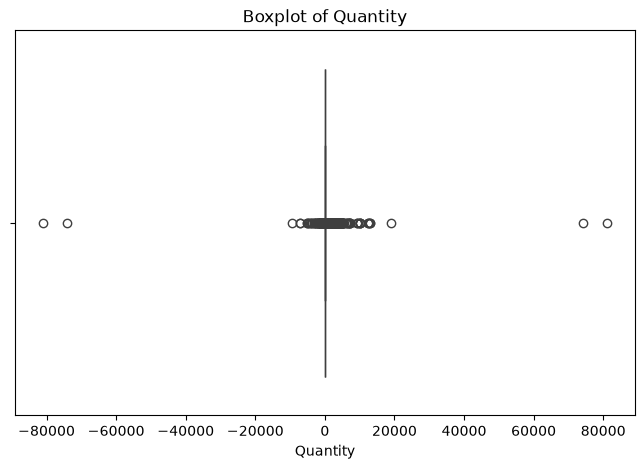

In [30]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['quantity'])
plt.title('Boxplot of Quantity')
plt.xlabel('Quantity')
plt.show()


Rows before filter: 794223
Rows after filter: 794219
Rows removed: 4

count    794219.000000
mean         12.652903
std          80.651825
min       -9360.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       19152.000000
Name: quantity, dtype: float64

Skewness: 71.85867169824373


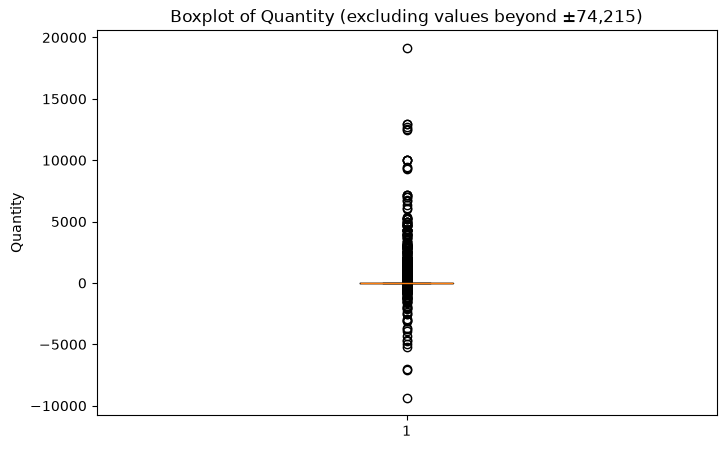

In [31]:
col = 'quantity'

# Keep only rows within ±74,215 (drop the two most extreme orders)
filtered = df[(df[col] > -74215) & (df[col] < 74215)]

print("Rows before filter:", len(df))
print("Rows after filter:", len(filtered))
print("Rows removed:", len(df) - len(filtered))
print()

print(filtered[col].describe())
print()
print("Skewness:", filtered[col].skew())

plt.figure(figsize=(8, 5))
plt.boxplot(filtered[col])
plt.title('Boxplot of Quantity (excluding values beyond ±74,215)')
plt.ylabel('Quantity')
plt.show()

* The typical row is somewhere between 2 and 12 units, that's the middle 50% of all rows (the 25th to 75th percentile). Each row is one product line on an invoice, not a whole order. Half of all rows are for 5 units or fewer. The mean is 12.65 (more than double the median which is 5.0) and standard deviation 192, meaning the distribution is hugely spread out. This indicates that the distribution is being driven by a small number of extreme values. The values range all the way from -80,995 to +80,995. The skewness score of 5.16 confirms this is nowhere close to a normal.
So the median (5 units) best describes the typical quantity per line when describing typical customer behavior.

* The top rows include 80,995 units of one paper craft item and 74,215 units of a ceramic jar, numbers no individual gift-buyer would order. At first these look like real bulk purchases by business customers, since many buyers are wholesalers. But the check further down shows each one was cancelled a short time after it was placed, with a matching negative row for the same customer and product. So they are mistakes that were entered and then reversed, not real sales. From the second boxplot where the outliers of values below -74215 and above 74215 have been removed, it helped with reducing the spread with std being 80 instead of 192, but the other statistics like median and mean are still the same, and skewness went up, not down (5.16 → 71.86). Removing a few extreme values doesn't make skewed data behave. Log-transform or capping before making this a customer-level feature would be the best way to handle this column.


* 17,586 rows have negative quantity, against 776,637 positive ones. These are tied to cancelled orders (C-invoices). When building each customer's total purchase behavior, we should let the negative and positive quantities net out naturally, so a customer who bought something and returned it isn't credited as if they kept the item.


In [32]:
# Do the C invoices match the negative quantities?
is_c_invoice = df['invoice_pattern'].str.startswith('L')
is_negative = df['quantity'] < 0

print("C-prefixed rows:", is_c_invoice.sum())
print("Negative-quantity rows:", is_negative.sum())
print("C invoice but positive quantity:", (is_c_invoice & ~is_negative).sum())
print("Negative quantity but no C:", (~is_c_invoice & is_negative).sum())

C-prefixed rows: 17586
Negative-quantity rows: 17586
C invoice but positive quantity: 0
Negative quantity but no C: 0


In [33]:
# Creating transaction type column based on 
df['transaction_type'] = df['quantity'].apply(lambda x: 'Purchased' if x > 0 else 'Cancelled')

print(df['transaction_type'].value_counts())

transaction_type
Purchased    776637
Cancelled     17586
Name: count, dtype: int64


##### Removing the two giant orders

The two largest rows (80,995 and 74,215 units) each have a matching cancellation for the same customer, product and quantity. Because we net purchases against cancellations, they would cancel out in spend. But the purchase invoice would still count as one order in frequency, so the customer would look more active than they were. We drop all four rows so neither the purchase nor the cancellation reaches the customer table.

In [34]:
# Looking at the two giant orders and their matching cancellations
giant = df[df['quantity'].abs() >= 74215]
print(giant[['invoice', 'stockcode', 'description', 'quantity', 'price', 'invoice_date', 'customer_id', 'transaction_type']])

        invoice stockcode                     description  quantity  price  \
433791   541431     23166  MEDIUM CERAMIC TOP STORAGE JAR     74215   1.04   
433796  C541433     23166  MEDIUM CERAMIC TOP STORAGE JAR    -74215   1.04   
797411   581483     23843     PAPER CRAFT , LITTLE BIRDIE     80995   2.08   
797412  C581484     23843     PAPER CRAFT , LITTLE BIRDIE    -80995   2.08   

              invoice_date customer_id transaction_type  
433791 2011-01-18 10:01:00       12346        Purchased  
433796 2011-01-18 10:17:00       12346        Cancelled  
797411 2011-12-09 09:15:00       16446        Purchased  
797412 2011-12-09 09:27:00       16446        Cancelled  


In [35]:
# Dropping the two giant orders and their cancellations
df = df[df['quantity'].abs() < 74215].reset_index(drop=True)

print(f"Rows remaining: {len(df):,}")

Rows remaining: 794,219


### Column: Price

In [36]:
col = 'price'

# ---- Statistical summary ----
print(df[col].describe())
print("Skewness:", df[col].skew())
print()
print("Zero-price rows:", (df[col] == 0).sum())
print("Negative-price rows:", (df[col] < 0).sum())
print()
print("Top 10 highest-priced rows:")
print(df.nlargest(10, col)[['stockcode', 'description', 'quantity', 'invoice_date', col]])

count    794219.000000
mean          2.971197
std           4.474935
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max         649.500000
Name: price, dtype: float64
Skewness: 32.388652246487446

Zero-price rows: 60
Negative-price rows: 0

Top 10 highest-priced rows:
       stockcode                   description  quantity        invoice_date  \
551147     22502    PICNIC BASKET WICKER SMALL        60 2011-06-10 15:28:00   
551156     22502    PICNIC BASKET WICKER SMALL         1 2011-06-10 15:33:00   
206165     22656  VINTAGE BLUE KITCHEN CABINET         1 2010-07-12 10:43:00   
206166     22655   VINTAGE RED KITCHEN CABINET         1 2010-07-12 10:43:00   
207694     22656  VINTAGE BLUE KITCHEN CABINET         1 2010-07-13 14:15:00   
208805     22656  VINTAGE BLUE KITCHEN CABINET         1 2010-07-15 08:46:00   
208934     22656  VINTAGE BLUE KITCHEN CABINET         1 2010-07-15 10:20:00   
211598     22655   VINTAGE RED KITCHEN CABINET

* Most items are cheap

The typical item costs £1.95 (that is the median, the 50% line).
The middle half of all items sit between £1.25 and £3.75.
The average is £2.97, which is higher than the median. That is a sign a few expensive items are pulling the average up.


* The most expensive item is £649.50. The skewness score is 32.4, which is very high. For comparison, quantity was 5.16.

* 60 rows have a price of £0. These are free items, usually samples, giveaways, replacements for damaged goods, or a stock adjustment someone logged as a sale. 60 rows out of 794,219 is tiny, so it will not change our results either way. But a £0 row means the customer received goods and paid nothing, so it counts as an order without counting as spend. That can slightly distort future analysis. The easy option is to drop them.

In [37]:
# Dropping the zero-price rows

df = df[df['price'] > 0].reset_index(drop=True)

print(f"Rows remaining: {len(df):,}")

Rows remaining: 794,159


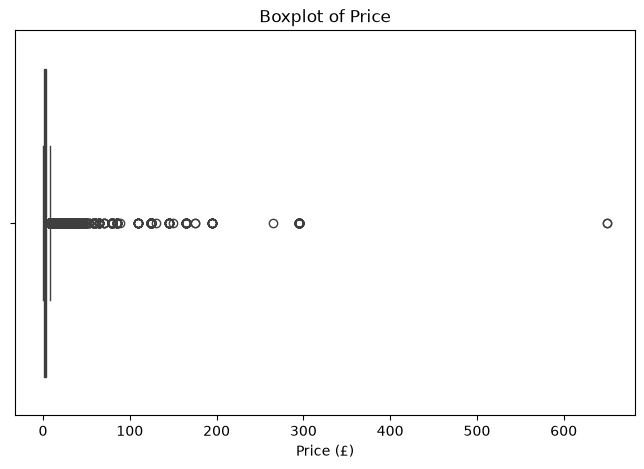

In [38]:
# Boxplot to visualize the price column
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')
plt.xlabel('Price (£)')
plt.show()

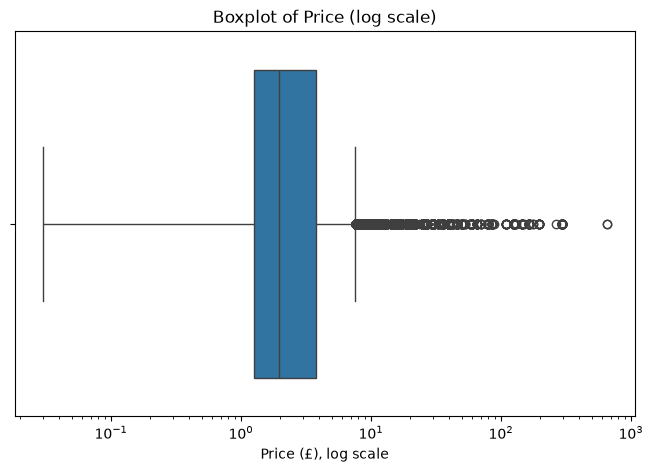

In [39]:
# Log-scale boxplot to visualize the price column

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['price'])
plt.xscale('log')
plt.title('Boxplot of Price (log scale)')
plt.xlabel('Price (£), log scale')
plt.show()

##### What the price boxplots show

On the normal scale the plot is unreadable. Every value is pressed against the left edge with a long trail of dots running right, which shows the shape of the skew rather than the data itself. The log-scale version is readable. Every outlier sits on the high side and none on the low side, so all of the stretch comes from the expensive end.

The whisker ends well below the highest prices, so the standard boxplot rule flags a large share of ordinary products as outliers simply because most items are cheap. Removing them would delete real sales. On the log scale the box is balanced and the median sits near the middle, which confirms a log transform is the right treatment for this column before it becomes a customer-level feature.

In [40]:
df.head()

,invoice,stockcode,description,quantity,invoice_date,price,customer_id,country,revenue,code_pattern,invoice_pattern,transaction_type
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,UK,83.4,DDDDD,DDDDDD,Purchased
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,UK,81.0,DDDDDL,DDDDDD,Purchased
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,UK,81.0,DDDDDL,DDDDDD,Purchased
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,UK,100.8,DDDDD,DDDDDD,Purchased
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,UK,30.0,DDDDD,DDDDDD,Purchased


In [41]:
# Dropping the pattern columns
df = df.drop(columns=['code_pattern', 'invoice_pattern'])

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['invoice', 'stockcode', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country', 'revenue', 'transaction_type']


In [42]:
df.head()

,invoice,stockcode,description,quantity,invoice_date,price,customer_id,country,revenue,transaction_type
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,UK,83.4,Purchased
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,UK,81.0,Purchased
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,UK,81.0,Purchased
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,UK,100.8,Purchased
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,UK,30.0,Purchased


In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 794159 entries, 0 to 794158
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   invoice           794159 non-null  str           
 1   stockcode         794159 non-null  str           
 2   description       794159 non-null  str           
 3   quantity          794159 non-null  int64         
 4   invoice_date      794159 non-null  datetime64[us]
 5   price             794159 non-null  float64       
 6   customer_id       794159 non-null  str           
 7   country           794159 non-null  str           
 8   revenue           794159 non-null  float64       
 9   transaction_type  794159 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(6)
memory usage: 102.3 MB


In [44]:
# Saving the clean transcation file for future model building
df.to_pickle("../data/online_retail_clean.pkl")

# EDA & Customer Lifecycle Segmentation

##### #### Defining the 90-day churn target

The target variable is a yes/no label on each customer. We pick a cutoff date, look only at what a customer did before this date, then look forward 90 days. If the customers from the observation windows placed no order in those 90 days after the cutoff date then they are labelled them churned (1). If they placed at least one they are labelled active (0). Everything the model learns from must come from before the cutoff, so nothing from the outcome/prediction window (90-days after cutoff date) leaks into the features.

*Why creating observation window and prediction window and not letting the model see the features of the prediction window matters*

In real use the shop runs the model on the cutoff date, when the next 90 days have not happened yet. The information the model was relying on does not exist at that point, so its accuracy drops sharply. Keeping every feature strictly before the cutoff means the test score reflects how the model will actually perform. If information from the prediction window slips into the features, the model is effectively given the answers during training. It will score very well in testing. Because it is reading and not predicting.



##### Two models : holiday and non-holiday

From the monthly revenue and customer volume chart shows that customers behave differently at Christmas. In October and November far more people buy, so a model trained on an ordinary part of the year would get the holiday season wrong. To handle this we build two models, one for ordinary months and one for the holiday period.

| Model | Observation window | Prediction window |
|---|---|---|
| Non-holiday | 1 Dec 2009 – 9 Jun 2011 | 10 Jun 2011 – 7 Sep 2011 |
| Holiday | 1 Dec 2009 – 8 Sep 2011 | 9 Sep 2011 – 7 Dec 2011 |

Both models use all the history available before their cutoff. Each model is tested by holding back a random share of customers, training on the rest, and checking how well it predicts the ones it has not seen.

In [45]:
# Building the churn label


def build_churn_label(df, cutoff, horizon_days=90):
    cutoff = pd.Timestamp(cutoff)
    pred_end = cutoff + pd.Timedelta(days=horizon_days)

    # everything before the cutoff
    df_obs = df[df['invoice_date'] < cutoff].copy()

    # only real purchases in the next 90 days
    purchases = df[df['transaction_type'] == 'Purchased']
    df_pred = purchases[(purchases['invoice_date'] >= cutoff) &
                        (purchases['invoice_date'] < pred_end)]

    # One row per customer who bought at least once before the cutoff
    obs_buyers = df_obs.loc[df_obs['transaction_type'] == 'Purchased', 'customer_id'].unique()
    labels = pd.DataFrame({'customer_id': obs_buyers})
    labels['churn_90d'] = (~labels['customer_id'].isin(df_pred['customer_id'])).astype(int)

    print(f"Cutoff {cutoff.date()} | prediction window {cutoff.date()} to {(pred_end - pd.Timedelta(days=1)).date()}")
    print(f"Customers labelled: {len(labels):,} | churn rate: {labels['churn_90d'].mean():.1%}")
    return df_obs, labels


# Non-holiday model
obs_nonhol, labels_nonhol = build_churn_label(df, '2011-06-10')

# Holiday model
obs_hol, labels_hol = build_churn_label(df, '2011-09-09')

Cutoff 2011-06-10 | prediction window 2011-06-10 to 2011-09-07
Customers labelled: 4,944 | churn rate: 68.0%
Cutoff 2011-09-09 | prediction window 2011-09-09 to 2011-12-07
Customers labelled: 5,253 | churn rate: 56.6%


##### How the churn label is built

The `build_churn_label` function takes a cutoff date and splits the data into two parts. Everything before the cutoff is the past, which we use later to build features. The 90 days after the cutoff is the future, which we only use to create the label.

For the future part, we only count real purchases, not cancellations, so a customer who only cancelled an order is not treated as someone who came back.

We then make one row for each customer who bought at least once before the cutoff. If they bought again in the next 90 days, they get a 0 (retained). If they did not, they get a 1 (churned).

In [46]:
# Checking how many new customers appear only in the prediction window
def count_new_customers(df, labels, cutoff, horizon_days=90):
    cutoff = pd.Timestamp(cutoff)
    pred_end = cutoff + pd.Timedelta(days=horizon_days)

    purchases = df[df['transaction_type'] == 'Purchased']
    pred_buyers = set(purchases.loc[(purchases['invoice_date'] >= cutoff) &
                                    (purchases['invoice_date'] < pred_end), 'customer_id'])
    obs_buyers = set(labels['customer_id'])
    new_customers = pred_buyers - obs_buyers

    print(f"Cutoff {cutoff.date()}")
    print(f"  Customers labelled (bought before cutoff): {len(obs_buyers):,}")
    print(f"  Customers who bought in the prediction window: {len(pred_buyers):,}")
    print(f"  Brand new customers we cannot score: {len(new_customers):,}")

count_new_customers(df, labels_nonhol, '2011-06-10')
count_new_customers(df, labels_hol, '2011-09-09')

Cutoff 2011-06-10
  Customers labelled (bought before cutoff): 4,944
  Customers who bought in the prediction window: 1,889
  Brand new customers we cannot score: 307
Cutoff 2011-09-09
  Customers labelled (bought before cutoff): 5,253
  Customers who bought in the prediction window: 2,873
  Brand new customers we cannot score: 595


In the non-holiday model, 307 customers are brand new, and in the holiday model 595 are brand new. These customers made their first purchase inside the prediction window, so they have no purchase history before the cutoff. Without that history we cannot calculate their recency, frequency or spend, so the model has nothing to base a prediction on.

Since these models will strictly be a retention model designed to predict if existing customers will churn or not. We cannot predict the retention of someone who just became our customer with their first purchase. Because the time split the model, the filtering out of these brand-new customers will happen naturally from the observation window. No calculation made features on the observation window will be able to guess these new customers future churn.

**This is for the universal limitation of both the models.**

### Testing whether churn rates differ between the holiday and non-holiday seasons

Before building two separate models, we check whether the churn rate is actually different between the two seasons.

- **H0:** The churn rate is the same in the holiday and non-holiday seasons.
- **H1:** The churn rate is different between the two seasons.

We use McNemar's test instead of a chi-square test because most customers appear in both groups, so the two groups are not independent. McNemar's test compares how each customer's label changed between the two cutoffs.

We use a 1% significance level. Because the sample is large, even a small difference in churn rates can come out as significant, so we also look at the size of the difference, not only the p-value.

This test is a starting point. It tells us whether the churn rates differ, but not whether customers behave differently in a way that needs a separate model. Once the models are built, we will train a model on the non-holiday data and use it to score the holiday customers, then compare it to a model trained on holiday data and scored on holiday customers it has not seen. If the non-holiday model does clearly worse on holiday customers, that is direct evidence a separate model is needed. If it does about as well, one model may be enough.

In [47]:
from statsmodels.stats.contingency_tables import mcnemar

# Customers who appear in both sets
both = labels_nonhol.merge(labels_hol, on='customer_id', suffixes=('_nonhol', '_hol'))

table = pd.crosstab(both['churn_90d_nonhol'], both['churn_90d_hol'])

table = table.rename(
    index={0: 'Retained', 1: 'Churned'},
    columns={0: 'Retained', 1: 'Churned'}
)
table.index.name = 'Non-holiday season'
table.columns.name = 'Holiday season'

# Run the test on the 2x2 table only, before any totals are added
result = mcnemar(table, exact=False, correction=True)

# Separate copy with totals, only for printing
table_display = table.copy()
table_display.loc['Total'] = table_display.sum()
table_display['Total'] = table_display.sum(axis=1)

print(table_display)

print(f"McNemar statistic: {result.statistic:.2f}, p-value: {result.pvalue:.4f}")

print(f"Non-holiday churn rate: {both['churn_90d_nonhol'].mean():.1%}")
print(f"Holiday churn rate:     {both['churn_90d_hol'].mean():.1%}")
print(f"Difference:             {(both['churn_90d_hol'].mean() - both['churn_90d_nonhol'].mean()):.1%}")

Holiday season      Retained  Churned  Total
Non-holiday season                          
Retained                1138      444   1582
Churned                  972     2390   3362
Total                   2110     2834   4944
McNemar statistic: 196.14, p-value: 0.0000
Non-holiday churn rate: 68.0%
Holiday churn rate:     57.3%
Difference:             -10.7%


##### What the McNemar test shows

The test covers 4,944 customers who appear in both groups. McNemar's test ignores the customers who had the same label both times (1,138 and 2,390), because they tell us nothing about a change between seasons. It only compares the two groups who switched: 972 versus 444. The p-value is below 0.0001, which is well under our 1% level, so we reject H0. The churn rates in the two seasons are not the same.

The size of the difference matters too. The churn rate is 68.0% in the non-holiday season and 57.3% in the holiday season, a gap of about 11 percentage points. That is large enough to matter in practice.

The table shows where the gap comes from. 972 customers churned in the non-holiday window but came back in the holiday window, while only 444 did the opposite. So many customers who go quiet in summer return to buy before Christmas.

This supports building two separate models. The model comparison after training should confirm this further.

In [48]:
display(labels_nonhol.head())
display(labels_hol.head())

,customer_id,churn_90d
0,13085,0
1,13078,0
2,15362,1
3,18102,0
4,12682,0


,customer_id,churn_90d
0,13085,1
1,13078,0
2,15362,1
3,18102,0
4,12682,0


### Customer Features Table

This groups the observation data by customer, so each customer gets one row. All features are calculated only from data before the cutoff date, and the table is built twice, once for each model with its own cutoff.

* **Recency:** Number of days between the customer's last purchase and the cutoff date.

* **Frequency:** Number of separate orders they placed. Cancelled orders are not counted.

* **Monetary:** Total amount they spent, after subtracting the value of any cancelled orders.

* **Product Breadth:** Number of different products they bought.

* **Average Order Value (AOV):** Average amount spent per order (Monetary divided by Frequency).

* **Average Basket Size:** Average number of items per order, after cancelled items are subtracted.

* **Customer Tenure:** Number of days between their first purchase and the cutoff date, meaning how long they have been a customer.

* **Cancellation Rate:** Share of all their orders that were cancellations (cancelled orders divided by purchase orders plus cancelled orders).

* **Country:** Whether they are a UK or non-UK buyer, based on the country that appears most often in their orders.

* **churn_90d:** The target. It comes from the label table built earlier and is joined to the features using customer ID. 1 means they did not buy in the 90 days after the cutoff, 0 means they did.

In [49]:
def build_features(df_obs, labels, cutoff):
    cutoff = pd.Timestamp(cutoff)
    purchases = df_obs[df_obs['transaction_type'] == 'Purchased']
    cancels = df_obs[df_obs['transaction_type'] == 'Cancelled']

    # Features from purchases only
    feats = purchases.groupby('customer_id').agg(
        first_purchase=('invoice_date', 'min'),
        last_purchase=('invoice_date', 'max'),
        frequency=('invoice', 'nunique'),
        product_breadth=('stockcode', 'nunique'),
    )

    # Spend and quantity after cancellations are netted out
    net = df_obs.groupby('customer_id').agg(
        monetary=('revenue', 'sum'),
        total_quantity=('quantity', 'sum'),
    )
    feats = feats.join(net)

    # Time-based features, measured from the cutoff
    feats['recency'] = (cutoff - feats['last_purchase']).dt.days
    feats['tenure'] = (cutoff - feats['first_purchase']).dt.days

    # Per-order averages
    feats['avg_order_value'] = feats['monetary'] / feats['frequency']
    feats['avg_basket_size'] = feats['total_quantity'] / feats['frequency']

    # Cancellation rate: what share of each customer's orders were cancellations.
    n_cancelled = cancels.groupby('customer_id')['invoice'].nunique().reindex(feats.index, fill_value=0)
    feats['cancellation_rate'] = n_cancelled / (feats['frequency'] + n_cancelled)

    # Most common country for each customer
    feats['country'] = df_obs.groupby('customer_id')['country'].agg(lambda s: s.mode().iloc[0])

    feats = feats.drop(columns=['first_purchase', 'last_purchase', 'total_quantity']).reset_index()

    # Join features onto the label table
    return labels.merge(feats, on='customer_id', how='left')


customer_data_nonhol = build_features(obs_nonhol, labels_nonhol, '2011-06-10')
customer_data_hol = build_features(obs_hol, labels_hol, '2011-09-09')

display(customer_data_nonhol.head())
display(customer_data_hol.head())

,customer_id,churn_90d,frequency,product_breadth,monetary,recency,tenure,avg_order_value,avg_basket_size,cancellation_rate,country
0,13085,0,7,46,2151.60,112,555,307.371429,113.142857,0.125000,UK
1,13078,0,41,131,20281.27,17,555,494.665122,188.707317,0.414286,UK
2,15362,1,2,38,613.08,265,555,306.540000,184.000000,0.000000,UK
3,18102,0,102,310,410880.97,0,555,4028.244804,1350.764706,0.019231,UK
4,12682,0,31,250,14347.59,9,555,462.825484,228.967742,0.031250,non-UK


,customer_id,churn_90d,frequency,product_breadth,monetary,recency,tenure,avg_order_value,avg_basket_size,cancellation_rate,country
0,13085,1,8,50,2289.58,65,646,286.197500,104.500000,0.111111,UK
1,13078,0,46,141,22709.73,14,646,493.689783,190.869565,0.417722,UK
2,15362,1,2,38,613.08,356,646,306.540000,184.000000,0.000000,UK
3,18102,0,112,311,454202.09,6,646,4055.375804,1323.946429,0.017544,UK
4,12682,0,40,280,17002.22,8,646,425.055500,209.725000,0.024390,non-UK


# Exploring the Holiday Customer Features Table for Customer Segmentation Analysis

In [50]:
data = customer_data_hol

# Statistical summary
display(data.describe().T)
print("Zero or negative monetary:", (data['monetary'] <= 0).sum())
print("Zero or negative avg order value:", (data['avg_order_value'] <= 0).sum())
print("Zero or negative basket size:", (data['avg_basket_size'] <= 0).sum())
print("Customers who never cancelled:", (data['cancellation_rate'] == 0).sum())
print("Customers who have not bought in over a year:", (data['recency'] > 365).sum())
print("Churn rate:", data['churn_90d'].mean().round(3))


,count,mean,std,min,25%,50%,75%,max
churn_90d,5253.0,0.566343,0.495626,0.00,0.000000,1.000000,1.000000,1.00
frequency,5253.0,5.703598,11.202232,1.00,1.000000,3.000000,6.000000,284.00
product_breadth,5253.0,74.474396,104.840674,1.00,18.000000,41.000000,92.000000,2178.00
monetary,5253.0,2515.021342,11803.454842,-1663.06,310.150000,758.990000,2004.010000,454202.09
recency,5253.0,205.729298,173.957719,0.00,49.000000,162.000000,324.000000,646.00
tenure,5253.0,429.917190,180.448394,0.00,309.000000,472.000000,585.000000,646.00
avg_order_value,5253.0,354.238780,493.253811,-1663.06,169.485000,268.270000,398.906667,13206.50
avg_basket_size,5253.0,237.494327,1388.524940,-1536.00,86.142857,146.153846,250.468750,87167.00
cancellation_rate,5253.0,0.114397,0.165906,0.00,0.000000,0.000000,0.208333,0.80


Zero or negative monetary: 10
Zero or negative avg order value: 10
Zero or negative basket size: 15
Customers who never cancelled: 3103
Customers who have not bought in over a year: 935
Churn rate: 0.566


In [51]:
# Churned vs retained, median of each feature (churn is not used to build the segments)
display(data.groupby('churn_90d').median(numeric_only=True).T)

churn_90d,0,1
frequency,5.000000,2.000000
product_breadth,72.000000,28.000000
monetary,1541.255000,467.340000
recency,65.000000,284.000000
tenure,499.000000,456.000000
avg_order_value,298.919643,239.120000
avg_basket_size,174.500000,129.928571
cancellation_rate,0.090909,0.000000


In [52]:
# Correlation between features
num_cols = data.select_dtypes('number').columns.drop('churn_90d')
display(data[num_cols].corr().round(2))

,frequency,product_breadth,monetary,recency,tenure,avg_order_value,avg_basket_size,cancellation_rate
frequency,1.00,0.69,0.63,-0.30,0.29,0.09,0.01,0.09
product_breadth,0.69,1.00,0.42,-0.33,0.30,0.15,0.03,0.12
monetary,0.63,0.42,1.00,-0.15,0.14,0.32,0.09,0.05
recency,-0.30,-0.33,-0.15,1.00,0.24,-0.06,0.01,-0.08
tenure,0.29,0.30,0.14,0.24,1.00,0.01,0.01,0.14
avg_order_value,0.09,0.15,0.32,-0.06,0.01,1.00,0.52,0.09
avg_basket_size,0.01,0.03,0.09,0.01,0.01,0.52,1.00,0.01
cancellation_rate,0.09,0.12,0.05,-0.08,0.14,0.09,0.01,1.00


In [53]:
# Spearman correlation works on ranks, so it is less affected by the skew
display(data[num_cols].corr(method='spearman').round(2))

,frequency,product_breadth,monetary,recency,tenure,avg_order_value,avg_basket_size,cancellation_rate
frequency,1.00,0.71,0.85,-0.57,0.53,0.20,0.18,0.37
product_breadth,0.71,1.00,0.77,-0.43,0.37,0.43,0.41,0.30
monetary,0.85,0.77,1.00,-0.52,0.44,0.66,0.56,0.38
recency,-0.57,-0.43,-0.52,1.00,0.12,-0.18,-0.19,-0.18
tenure,0.53,0.37,0.44,0.12,1.00,0.10,0.07,0.23
avg_order_value,0.20,0.43,0.66,-0.18,0.10,1.00,0.83,0.20
avg_basket_size,0.18,0.41,0.56,-0.19,0.07,0.83,1.00,0.16
cancellation_rate,0.37,0.30,0.38,-0.18,0.23,0.20,0.16,1.00


##### What the holiday features table shows

This table is a snapshot of each customer as of 9 Sept 2011. We use the September snapshot because it lets us check the churn rate of each segment in the 90 days after, which shows whether the groups mean something.

**Size and churn rate**

The table has 5,253 customers, and 56.6% of them churned (did not buy in the 90 days after 9 Sept 2011). Churn is not used to build the segments. Once the segments are made, we will look at the churn rate in each one.

**How the features are spread**

- Comparing the mean, median and max of each column, we can see that most features are heavily skewed. For frequency, monetary, product breadth, average order value and basket size, the mean is well above the median, and the maximum is far above the 75th percentile. For example, the median customer spent £759, the average is £2,515, and the top customer spent £454,202. A small number of large buyers, likely wholesalers, pull the averages up. These features will need a log transform before clustering.
- Many customers buy only once. At least a quarter of customers have a frequency of 1, and the median is 3 orders.
- Recency varies widely. A quarter of customers bought in the last 49 days, while another quarter have not bought in over 323 days. 935 customers have not bought in over a year. They will likely form their own group of "used to buy but has gone quiet" customers.
- Tenure tops out at 646 days, which is the full length of the data before the cutoff. Customers at that value were already buying when the data starts, so their real tenure may be longer.
- Most customers never cancel. The median cancellation rate is 0, though some customers cancelled up to 80% of their orders. 3,103 customers (59%) never cancelled. If cancellation rate goes into the clustering, it would mostly split customers into "cancels" and "doesn't cancel", so we leave it out and compare it across segments afterwards.
- 10 customers have zero or negative spend. This happens when cancellations are larger than purchases, often because the original order was placed before the data starts. Their average order value is also negative. Another 5 customers have positive spend but a zero or negative basket size, because they cancelled more items than they bought. All 15 are dropped, since their values don't reflect real buying and the log transform does not work on negative values.
- Country is a UK / non-UK flag (4,796 UK, 457 non-UK). A yes/no column doesn't sit well with distance-based clustering, so we leave it out and compare it across segments afterwards.

**Churned vs retained customers (medians, background only)**

This part is kept as background for our ML model. It is not used to build the segments.

- Recency shows the biggest gap. 50% of retained customers last bought 65 days before the cutoff, whereas 50% of churned customers 284 days before. How recently someone bought is likely to be the strongest signal for the model.
- Retained customers buy more often and more widely. They placed 5 orders compared to 2 orders placed by churned customers. Retained also bought 72 different products compared to 28 different products by churned, and spent about three times as much (£1,541 vs £467).
- Order size differs less. Retained customers spend a bit more per order (£299 vs £239) and buy slightly larger baskets (175 vs 130 items), but the gap is much smaller than for frequency or total spend.
- Tenure is similar for both groups (499 vs 456 days), so how long someone has been a customer says less about churn than how active they are.
- Retained customers cancel more (median rate 9% vs 0%). This is likely because they place more orders, so they have more chances to cancel, rather than cancelling being a good sign in itself.

**Correlation between features**

- Frequency is linked to product breadth (0.69) and monetary (0.63), since customers who order more often tend to buy more products and spend more.
- Average order value and basket size are linked (0.52), since bigger baskets usually cost more.
- Recency has a weak negative link with frequency and breadth (around -0.3), meaning frequent buyers tend to be more recent customers too.
- These numbers use Pearson correlation, which is sensitive to extreme values. The Spearman version (based on ranks) gives a different picture. Frequency and monetary go up to 0.85, average order value and basket size to 0.83, and frequency and product breadth to 0.71. Recency's link with frequency also gets stronger (-0.57).
- So once the skew is taken out, three pairs are above 0.7. These pairs carry much of the same information. Grouping customers by distance, so two features that say the same thing count that information twice. With frequency and monetary at 0.85, "how much they buy" would get double weight over everything else. So we should check the correlations again after the log transform and drop one feature from each highly linked pair.

**From these findings**

1. Drop the 15 customers with zero or negative spend on order value or basket size.
2. Leave churn, country and cancellation rate out of the clustering, and use them afterwards to describe the segments.
3. Apply a log transform to the skewed features (frequency, product breadth, monetary, average order value, basket size). Recency and tenure are not skewed enough to need one.
4. Recheck the correlations after the log transform and drop one feature from each highly linked pair.
5. Scale all the features so each one counts the same in the clustering.

### Customer Segmentation with RFM Scoring

We are now using a rule-based scoring system (RFM) instead. Each customer gets a score from 1 to 4 on a few features, and a set of plain rules turns those scores into segments.


### The features we score

| Score | Feature | Better when |
|---|---|---|
| R | Recency (days since last purchase) | Lower |
| F | Frequency (number of orders) | Higher |
| M | Monetary (total net spend) | Higher |
| Breadth score | Product breadth (number of different products) | Higher |
| AOV score | Average order value | Higher |

R, F and M decide the segment. Breadth and AOV are added to a total score, which gives one number per customer that we can also pass to the churn model later. Tenure and basket size are not scored, but we use them to describe the segments.

In [54]:
# Working on a copy of the holiday customer table
rfm = data.copy()


# Quartile cut-offs (25th, 50th and 75th percentile) for each feature we score
score_cols = ['recency', 'frequency', 'monetary', 'product_breadth', 'avg_order_value']
cutoffs = rfm[score_cols].quantile([0.25, 0.50, 0.75])

cutoffs

,recency,frequency,monetary,product_breadth,avg_order_value
0.25,49.0,1.0,310.15,18.0,169.485000
0.50,162.0,3.0,758.99,41.0,268.270000
0.75,324.0,6.0,2004.01,92.0,398.906667


##### What the cut-offs mean

Each column shows the three values that split customers into four equal-sized groups. For example, for recency a quarter of customers bought in the last 49 days, half bought in the last 162 days, and a quarter have not bought in more than 323 days.

Frequency has many repeated values. The 25th percentile is 1 order, so every one-time buyer (about 30% of customers) falls in the bottom group. That makes the frequency groups a little uneven in size, which is fine because the rule still reads plainly like one order, two to three orders, four to six orders, or seven or more.

In [55]:
# Scoring functions

# For features where a higher value is better (frequency, monetary, breadth, AOV)
def high_is_good(value, col):
    if value <= cutoffs.loc[0.25, col]:
        return 1
    elif value <= cutoffs.loc[0.50, col]:
        return 2
    elif value <= cutoffs.loc[0.75, col]:
        return 3
    else:
        return 4

# For recency, where a lower value (fewer days since last purchase) is better
def low_is_good(value, col):
    return 5 - high_is_good(value, col)

These two functions turn a raw value into a score from 1 to 4.

- `high_is_good` gives 4 to the top 25% of customers and 1 to the bottom 25%.
- `low_is_good` flips that for recency, so customers who bought most recently get 4 and those who have been away the longest get 1.

In [56]:
# Giving each customer a 1-4 score on every feature
rfm['R'] = rfm['recency'].apply(low_is_good, args=('recency',))
rfm['F'] = rfm['frequency'].apply(high_is_good, args=('frequency',))
rfm['M'] = rfm['monetary'].apply(high_is_good, args=('monetary',))
rfm['breadth_score'] = rfm['product_breadth'].apply(high_is_good, args=('product_breadth',))
rfm['aov_score'] = rfm['avg_order_value'].apply(high_is_good, args=('avg_order_value',))

# How many customers got each score
score_counts = rfm[['R', 'F', 'M', 'breadth_score', 'aov_score']].apply(pd.Series.value_counts)
score_counts.index.name = 'score'
score_counts

,R,F,M,breadth_score,aov_score
score,,,,,
1,1304,1576,1314,1364,1314
2,1321,1465,1313,1283,1313
3,1303,977,1313,1303,1313
4,1325,1235,1313,1303,1313


Every score except F splits customers into four groups of roughly 1,300 each, as expected from quartiles. F is uneven for the reason given above: 1,567 one-time buyers all get F score of 1.

### Building the segments

We join R, F and M into a 3-digit code (for example "444" or "121"), then group the codes into five segments. F and M are added together into one value score from 2 to 8, because both measure how much a customer is worth to the shop. The rules are checked from top to bottom, and a customer goes into the first segment whose rule they meet.

| Segment | Rule | In plain words |
|---|---|---|
| Champions | R = 4 and F + M ≥ 7 | Bought very recently and near the top on value |
| Loyal | R ≥ 3 and F + M ≥ 5 | Bought recently and solid value |
| Needs Attention | R ≥ 3 | Bought recently but low value so far |
| At Risk | F + M ≥ 6 | Used to be valuable but has not bought for a while |
| Lapsed | Everyone else | Not recent and low value |

We also add up all five scores into a total score, from 5 (lowest) to 20 (highest).

In [57]:
# The 3-digit RFM code
rfm['rfm_code'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

# Turning the scores into segments
def assign_segment(row):
    r = row['R']
    value = row['F'] + row['M']   # value score from 2 to 8

    if r == 4 and value >= 7:
        return 'Champions'
    elif r >= 3 and value >= 5:
        return 'Loyal'
    elif r >= 3:
        return 'Needs Attention'
    elif value >= 6:
        return 'At Risk'
    else:
        return 'Lapsed'

rfm['segment'] = rfm.apply(assign_segment, axis=1)

# Total score from all five scores (5 to 20)
rfm['total_score'] = rfm['R'] + rfm['F'] + rfm['M'] + rfm['breadth_score'] + rfm['aov_score']

rfm[['customer_id', 'recency', 'frequency', 'monetary', 'rfm_code', 'segment', 'total_score']].head(10)

,customer_id,recency,frequency,monetary,rfm_code,segment,total_score
0,13085,65,8,2289.58,344,Loyal,17
1,13078,14,46,22709.73,444,Champions,20
2,15362,356,2,613.08,122,Lapsed,10
3,18102,6,112,454202.09,444,Champions,20
4,12682,8,40,17002.22,444,Champions,20
5,18087,198,16,13563.62,244,At Risk,17
6,13635,350,3,1877.19,123,Lapsed,13
7,14110,27,26,10536.07,444,Champions,20
8,17519,41,14,4413.20,444,Champions,19
9,13758,109,12,7705.26,344,Loyal,19


In [58]:
# Fixed order for the segments, used in every table and chart below
segment_order = ['Champions', 'Loyal', 'Needs Attention', 'At Risk', 'Lapsed']

# How many customers are in each segment
segment_sizes = pd.DataFrame({
    'customers': rfm['segment'].value_counts(),
    'share_%': (rfm['segment'].value_counts(normalize=True) * 100).round(1)
}).reindex(segment_order)

segment_sizes

,customers,share_%
segment,,
Champions,786,15.0
Loyal,1120,21.3
Needs Attention,722,13.7
At Risk,495,9.4
Lapsed,2130,40.5


##### Segment sizes

Lapsed is the biggest group by far, with 2,118 customers (40.4%). Loyal is next at 1,117 (21.3%), then Champions at 786 (15.0%), Needs Attention at 724 (13.8%), and At Risk is the smallest at 493 (9.4%).

So about half of the customer base (At Risk plus Lapsed) had not bought recently as of 9 Sept 2011. This fits what we saw earlier: a quarter of customers had not bought in more than 323 days.

### Describing each segment

Next we look at the typical (median) customer in each segment. We use the median because most features are heavily skewed, and a few large wholesale buyers would pull the mean up.

In [59]:
# Median of each feature per segment
segment_profile = rfm.groupby('segment')[['recency', 'frequency', 'monetary', 'product_breadth',
                                          'avg_order_value', 'avg_basket_size', 'tenure', 'total_score']].median()

segment_profile = segment_profile.reindex(segment_order).round(1)
segment_profile

,recency,frequency,monetary,product_breadth,avg_order_value,avg_basket_size,tenure,total_score
segment,,,,,,,,
Champions,16.0,12.0,4428.8,140.0,352.6,208.3,586.0,19.0
Loyal,78.0,5.0,1496.2,72.0,309.3,179.5,511.0,15.0
Needs Attention,70.0,2.0,341.6,22.0,206.5,111.5,125.0,10.0
At Risk,284.0,5.0,1764.7,75.0,310.5,168.8,581.0,14.0
Lapsed,336.0,1.0,327.7,22.0,219.9,120.0,437.0,9.0


##### What the segment profile shows

- **Champions** last bought 16 days before the cutoff, have placed 12 orders, spent £4,429, and bought 140 different products. They also have the highest order value (£353) and basket size (208 items). They have been customers for 586 days, close to the full length of the data.
- **Loyal** customers are recent (78 days) with 5 orders and £1,499 spent. They look like a smaller version of Champions.
- **Needs Attention** customers are recent (70 days) but have only 2 orders and £343 spent. Their tenure is only 125 days, much shorter than any other group. Many of them are new customers who have not built up a history yet.
- **At Risk** customers placed 5 orders and spent £1,765, which is more than the Loyal group. But their last purchase was 284 days before the cutoff. On history they look like good customers, they have just gone quiet.
- **Lapsed** customers last bought 336 days before the cutoff, placed 1 order and spent £329. Most of them bought once and never came back.

The total score goes down in almost the same order as the segments (19, 15, 10, 14, 9). At Risk scores higher than Needs Attention, because their high F and M make up for their low R.

### Customer value by segment

Here we look at how much each segment has spent in total up to the cutoff (historical customer value) and what share of all revenue it brought in.

In [60]:
# Historical spend per segment
segment_value = rfm.groupby('segment')['monetary'].agg(
    customers='count',
    mean_spend='mean',
    median_spend='median',
    total_spend='sum'
).reindex(segment_order)

segment_value['share_of_customers_%'] = (segment_value['customers'] / segment_value['customers'].sum() * 100)
segment_value['share_of_revenue_%'] = (segment_value['total_spend'] / segment_value['total_spend'].sum() * 100)

segment_value.round(1)

,customers,mean_spend,median_spend,total_spend,share_of_customers_%,share_of_revenue_%
segment,,,,,,
Champions,786,10035.2,4428.8,7887664.1,15.0,59.7
Loyal,1120,2386.4,1496.2,2672808.5,21.3,20.2
Needs Attention,722,380.6,341.6,274791.2,13.7,2.1
At Risk,495,2863.7,1764.7,1417552.2,9.4,10.7
Lapsed,2130,450.0,327.7,958591.1,40.5,7.3


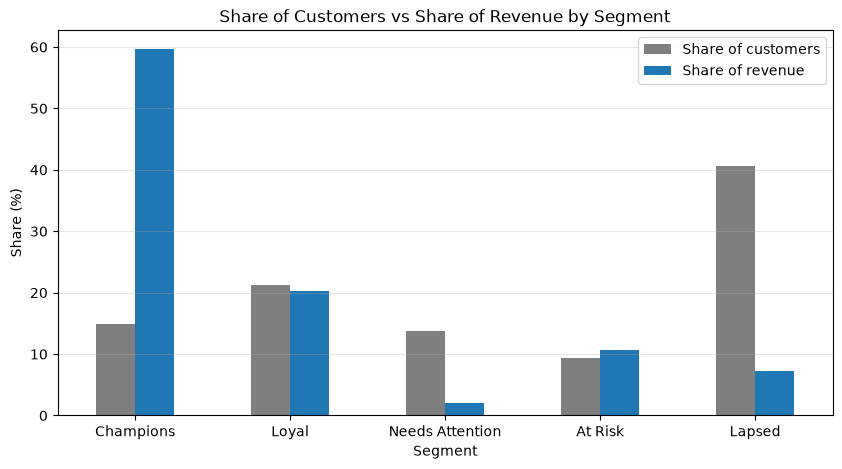

In [61]:
# Share of customers vs share of revenue for each segment
share_table = segment_value[['share_of_customers_%', 'share_of_revenue_%']]

share_table.plot(kind='bar', figsize=(10, 5), color=['tab:gray', 'tab:blue'])
plt.title('Share of Customers vs Share of Revenue by Segment')
plt.xlabel('Segment')
plt.ylabel('Share (%)')
plt.xticks(rotation=0)
plt.legend(['Share of customers', 'Share of revenue'])
plt.grid(axis='y', alpha=0.3)
plt.show()

##### What the value table and chart show

- **Champions** are 15.0% of customers but brought in 59.7% of revenue up to the cutoff. The median Champion has spent £4,429. The mean (£10,035) is more than twice the median, so a few very large buyers sit in this group.
- **Loyal** customers are 21.3% of customers and 20.2% of revenue, so their share of revenue matches their size.
- **At Risk** customers are 9.4% of customers but 10.7% of revenue. Their median spend (£1,765) is higher than Loyal (£1,499). Each At Risk customer who does not come back costs the shop more, on average, than a Loyal customer.
- **Needs Attention** and **Lapsed** together are 54.2% of customers but only 9.4% of revenue. The median spend in both is around £330–£345.

Champions and Loyal together bring in about 80% of the revenue. Keeping these customers buying matters more for revenue than winning back the Lapsed group.

### Churn rate by segment

Churn was not used to build the segments. Now we check whether the segments line up with what actually happened in the 90 days after the cutoff (9 Sept to 7 Dec 2011). If they do, the segments describe real differences in behaviour.

segment
Champions          16.0
Loyal              39.6
Needs Attention    56.0
At Risk            60.4
Lapsed             79.9
Name: churn_90d, dtype: float64
Overall churn rate: 56.6%


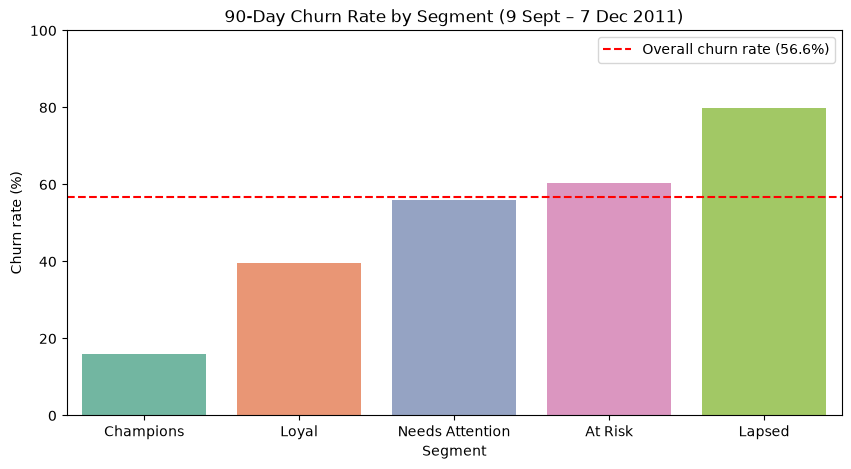

In [62]:
# Churn rate in each segment
churn_by_segment = (rfm.groupby('segment')['churn_90d'].mean() * 100).reindex(segment_order)
overall_churn = rfm['churn_90d'].mean() * 100

print(churn_by_segment.round(1))
print(f"Overall churn rate: {overall_churn:.1f}%")

plt.figure(figsize=(10, 5))
sns.barplot(x=churn_by_segment.index, y=churn_by_segment.values,
            hue=churn_by_segment.index, palette='Set2', legend=False)
plt.axhline(overall_churn, color='red', linestyle='--', label=f'Overall churn rate ({overall_churn:.1f}%)')
plt.title('90-Day Churn Rate by Segment (9 Sept – 7 Dec 2011)')
plt.xlabel('Segment')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.show()

##### What the churn rate chart shows

The churn rate goes up step by step from Champions to Lapsed:

- **Champions:** 16.0%. More than 8 in 10 bought again in the next 90 days.
- **Loyal:** 39.7%, well below the overall rate of 56.5%.
- **Needs Attention:** 55.8%, about the same as the overall rate.
- **At Risk:** 60.4%, a little above the overall rate.
- **Lapsed:** 79.8%. Only about 1 in 5 came back.

The segments were built without looking at churn, yet they sort customers from lowest to highest churn. This tells us the rules are picking up real differences in how likely customers are to come back.

One thing to keep in mind is that this window covers the run-up to Christmas. From the McNemar test we know many customers who go quiet in summer come back before Christmas. So the churn rates here, especially for At Risk and Lapsed, are likely lower than they would be at other times of the year.

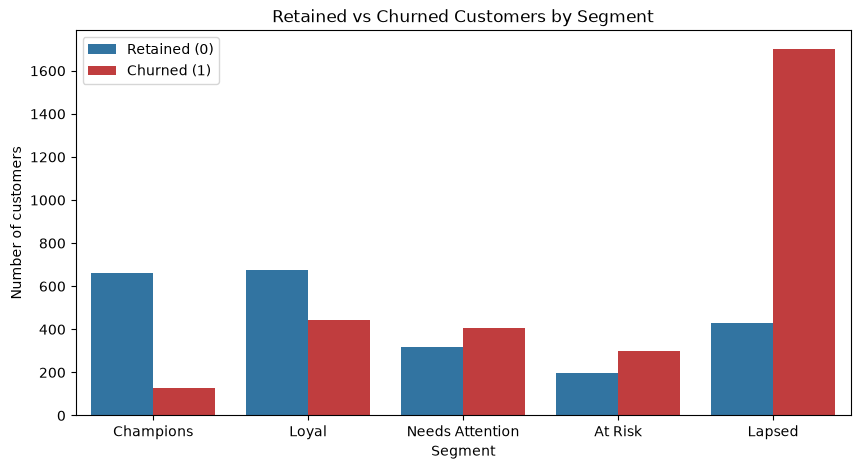

churn_90d,0,1
segment,,
Champions,660,126
Loyal,676,444
Needs Attention,318,404
At Risk,196,299
Lapsed,428,1702


In [63]:
# Number of churned and retained customers in each segment
plt.figure(figsize=(10, 5))
sns.countplot(data=rfm, x='segment', hue='churn_90d', order=segment_order,
              palette={0: 'tab:blue', 1: 'tab:red'})
plt.title('Retained vs Churned Customers by Segment')
plt.xlabel('Segment')
plt.ylabel('Number of customers')
plt.legend(title='', labels=['Retained (0)', 'Churned (1)'])
plt.show()

pd.crosstab(rfm['segment'], rfm['churn_90d']).reindex(segment_order)

##### What the churn count chart shows

The rate chart shows how likely a customer in each group is to churn. This chart shows how many customers that is.

- **Lapsed** has 1,691 churned customers, more than every other segment put together (1,271). Most of the customers the shop loses are in this group, but as the value table showed, they are low spenders.
- **Loyal** has 443 churned customers. This is the second largest number, and these customers have a median spend of about £1,500. This group is worth watching.
- **At Risk** has 298 churned and 195 retained. The group is small, but these are high-value customers.
- **Champions** is the only group where retained customers (660) are far more than churned ones (126).

### Does the total score line up with churn?

The total score adds up all five scores into one number. If the score is useful, customers with a higher score should churn less.

             customers  churn_rate
total_score                       
5                  236        92.8
6                  346        87.6
7                  318        81.1
8                  320        71.2
9                  359        77.2
10                 413        70.7
11                 344        65.7
12                 367        57.8
13                 393        59.8
14                 393        59.8
15                 344        45.6
16                 287        35.5
17                 261        32.2
18                 320        23.1
19                 346        15.3
20                 206         9.7


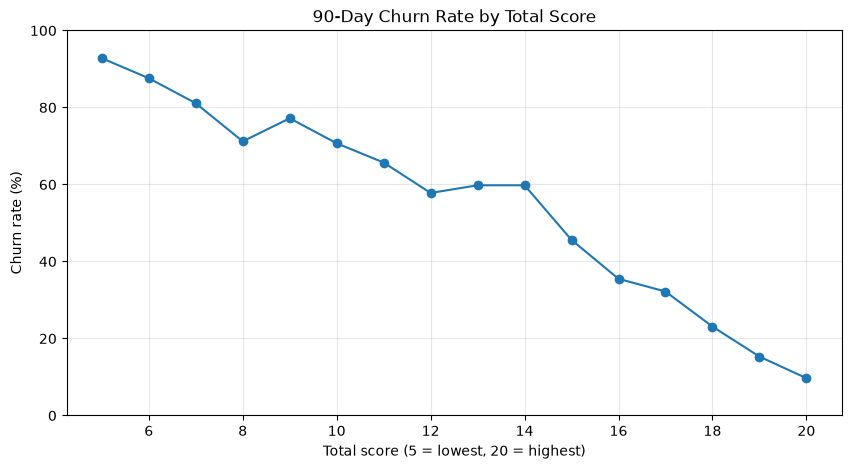

In [64]:
# Churn rate for each total score
score_churn = rfm.groupby('total_score')['churn_90d'].agg(customers='size', churn_rate='mean')
score_churn['churn_rate'] = (score_churn['churn_rate'] * 100).round(1)
print(score_churn)

plt.figure(figsize=(10, 5))
plt.plot(score_churn.index, score_churn['churn_rate'], marker='o')
plt.title('90-Day Churn Rate by Total Score')
plt.xlabel('Total score (5 = lowest, 20 = highest)')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

##### What the total score chart shows

Churn falls as the total score goes up. Customers with the lowest score of 5 churned 92.2% of the time, while those with the highest score of 20 churned only 9.8% of the time. The line is not perfectly smooth (for example 8 and 9, or 12 to 14 sit at about the same level), but the overall direction is clear.

Because it lines up with churn, the total score is a simple single number the shop can use to rank customers, and it can also be tested as a feature in the churn model.

### Churn by days since last purchase

Recency showed the biggest gap between churned and retained customers earlier. Here we split recency into bands to see how churn changes as customers go longer without buying.

              customers  churn_rate
recency_band                       
0-30                949        24.8
31-60               555        32.3
61-90               399        44.4
91-120              382        45.0
121-180             490        62.2
181-270             454        67.8
271-365            1089        70.2
365+                935        89.3


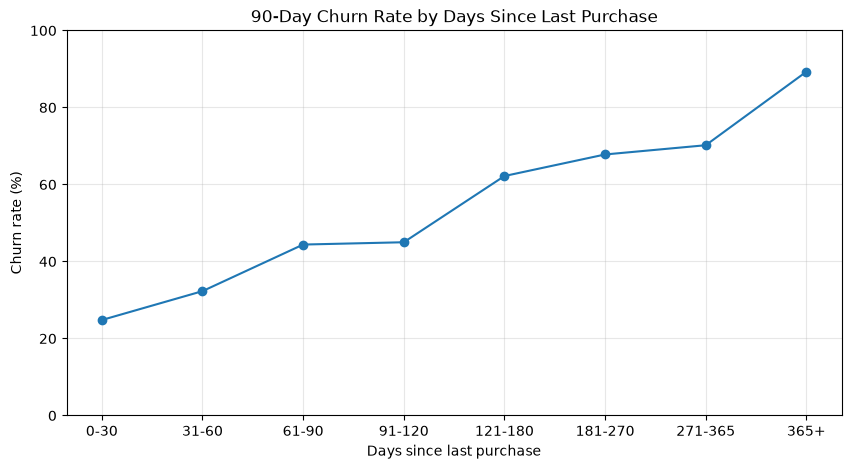

In [65]:
# Splitting recency into bands
recency_bins = [0, 30, 60, 90, 120, 180, 270, 365, rfm['recency'].max() + 1]
recency_labels = ['0-30', '31-60', '61-90', '91-120', '121-180', '181-270', '271-365', '365+']

rfm['recency_band'] = pd.cut(rfm['recency'], bins=recency_bins, labels=recency_labels, include_lowest=True)

recency_churn = rfm.groupby('recency_band', observed=True)['churn_90d'].agg(customers='size', churn_rate='mean')
recency_churn['churn_rate'] = (recency_churn['churn_rate'] * 100).round(1)
print(recency_churn)

plt.figure(figsize=(10, 5))
plt.plot(recency_churn.index.astype(str), recency_churn['churn_rate'], marker='o')
plt.title('90-Day Churn Rate by Days Since Last Purchase')
plt.xlabel('Days since last purchase')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

##### What the recency chart shows

- Customers who bought in the last 30 days have the lowest churn rate 24.8%.
- Churn goes up to 32.3% at 31–60 days and then to about 45% at 61–120 days.
- The biggest jump is after 120 days, where churn goes from 45.0% to 62.2%. After four months without buying, a customer is more likely to churn than to come back.
- After a year (365+ days), 89.5% churn. Only about 1 in 10 of these customers bought again.

The 271–365 day band holds the most customers (1,082). Together with the 365+ band, that is 2,011 customers who had not bought for more than 9 months.

For the shop, this suggests contacting customers before they reach about 120 days without an order, rather than waiting until they have been gone for most of a year.

### One-time, two-time and repeat buyers

About 30% of customers bought only once. Here we compare them with customers who bought twice and those who bought three or more times.

                    customers  churn_rate  median_spend
buyer_type                                             
One-time buyers          1576        79.6        228.32
Two-time buyers           892        67.4        491.48
Repeat buyers (3+)       2785        40.2       1778.10


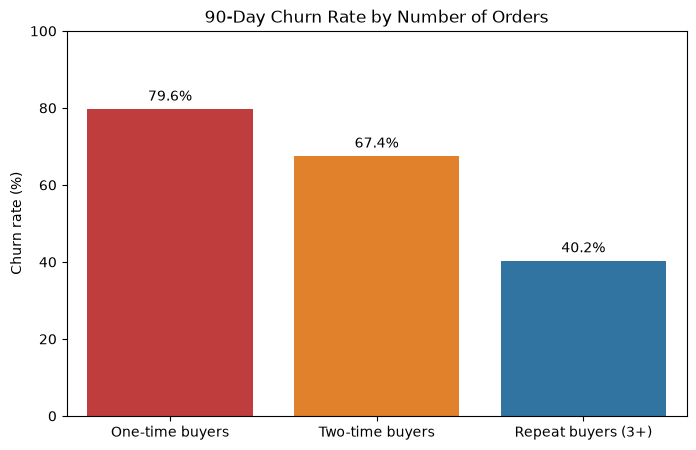

In [66]:
# Grouping customers by how many orders they have placed
def buyer_type(freq):
    if freq == 1:
        return 'One-time buyers'
    elif freq == 2:
        return 'Two-time buyers'
    else:
        return 'Repeat buyers (3+)'

rfm['buyer_type'] = rfm['frequency'].apply(buyer_type)
buyer_order = ['One-time buyers', 'Two-time buyers', 'Repeat buyers (3+)']

buyer_summary = rfm.groupby('buyer_type').agg(
    customers=('churn_90d', 'size'),
    churn_rate=('churn_90d', 'mean'),
    median_spend=('monetary', 'median')
).reindex(buyer_order)
buyer_summary['churn_rate'] = (buyer_summary['churn_rate'] * 100).round(1)
print(buyer_summary)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=buyer_summary.index, y=buyer_summary['churn_rate'],
                 hue=buyer_summary.index, palette=['tab:red', 'tab:orange', 'tab:blue'], legend=False)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height()}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points')
plt.title('90-Day Churn Rate by Number of Orders')
plt.xlabel('')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.show()

##### What the buyer type chart shows

- **One-time buyers** (1,561 customers) churned 79.5% of the time and have a median spend of £231.
- **Two-time buyers** (892) churned 67.4% of the time, with a median spend of £491.
- **Repeat buyers** with 3 or more orders (2,785) churned 40.2% of the time, with a median spend of £1,778.

The second order lowers churn by about 12 percentage points, and the third order lowers it by another 27. So the larger change comes at the third order. Getting a new customer to place a second and then a third order looks like one of the main ways to keep them.

This links to the segments. Of the 724 Needs Attention customers, 343 are one-time buyers and 254 are two-time buyers. These are the customers who could still be moved towards the repeat group.

In [67]:
# How the buyer types are spread across the segments
pd.crosstab(rfm['segment'], rfm['buyer_type']).reindex(index=segment_order, columns=buyer_order)

buyer_type,One-time buyers,Two-time buyers,Repeat buyers (3+)
segment,,,
Champions,0,0,786
Loyal,2,95,1023
Needs Attention,344,251,127
At Risk,0,21,474
Lapsed,1230,525,375


Champions are all repeat buyers, and nearly all Loyal and At Risk customers are too. Lapsed is mostly one-time buyers (1,216 of 2,118). Needs Attention is the only recent segment with a large number of one- and two-time buyers, which matches its short tenure.

### Average order value by segment

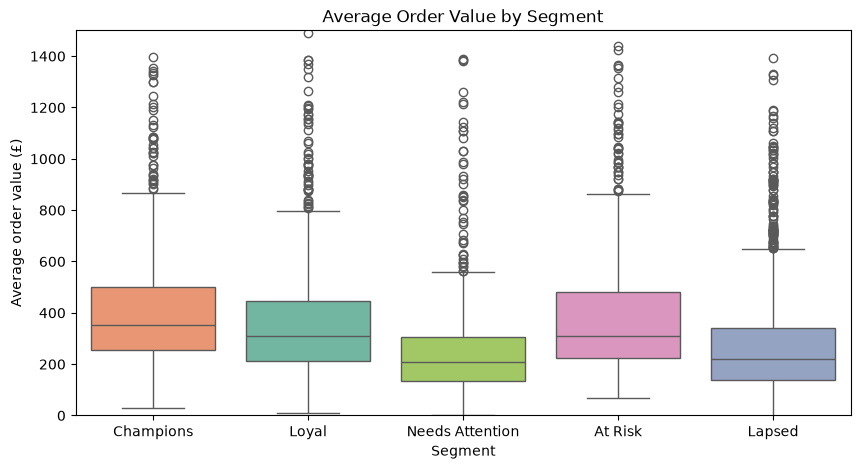

,count,mean,std,min,25%,50%,75%,max
segment,,,,,,,,
Champions,786.0,460.9,472.3,29.7,253.5,352.6,500.1,6691.9
Loyal,1120.0,408.2,600.2,11.2,213.5,309.3,447.6,13206.5
Needs Attention,722.0,253.8,211.8,-200.8,134.9,206.5,304.4,1706.9
At Risk,495.0,458.4,489.8,67.9,224.7,310.5,480.7,6075.1
Lapsed,2130.0,296.4,492.6,-1663.1,137.4,219.9,342.3,11880.8


In [68]:
# Average order value by segment
plt.figure(figsize=(10, 5))
sns.boxplot(data=rfm, x='segment', y='avg_order_value', order=segment_order,
            hue='segment', palette='Set2', legend=False)
plt.ylim(0, 1500)   # capping the axis so the boxes are readable
plt.title('Average Order Value by Segment')
plt.xlabel('Segment')
plt.ylabel('Average order value (£)')
plt.show()

rfm.groupby('segment')['avg_order_value'].describe().reindex(segment_order).round(1)

##### What the order value chart shows

The y-axis is capped at £1,500 so the boxes can be read from the visualization. A few customers in each group spend far more per order than that.

- **Champions** have the highest typical order value (median £353), with the middle half between about £253 and £500.
- **Loyal** (£309) and **At Risk** (£310) are almost the same. So the At Risk customers were not small buyers. When they did buy, they spent as much per order as Loyal customers.
- **Needs Attention** (£207) and **Lapsed** (£221) have the lowest order values.

Every segment has a long tail of high values, reaching up to £13,206 per order in Loyal. These are most likely wholesale buyers placing large orders.

### Country and cancellations by segment

Country and cancellation rate were left out of the scoring. Here we check whether they differ between segments.

In [69]:
# Share of non-UK customers and cancellation behaviour in each segment
extra_profile = rfm.groupby('segment').agg(
    non_uk_share=('country', lambda s: (s == 'non-UK').mean() * 100),
    ever_cancelled_share=('cancellation_rate', lambda s: (s > 0).mean() * 100),
    median_cancellation_rate=('cancellation_rate', 'median')
).reindex(segment_order).round(2)

extra_profile

,non_uk_share,ever_cancelled_share,median_cancellation_rate
segment,,,
Champions,9.03,79.39,0.14
Loyal,10.98,58.66,0.14
Needs Attention,8.86,15.93,0.00
At Risk,7.27,59.39,0.14
Lapsed,7.65,21.60,0.00


##### What the country and cancellation table shows

- **Country:** Non-UK customers make up between 7.3% and 10.9% of each segment. There is no segment made up mostly of overseas buyers, so country does not change much between groups.
- **Cancellations:** 79.4% of Champions have cancelled at least once, compared with 16.2% of Needs Attention and 21.1% of Lapsed. Loyal and At Risk sit in the middle at about 59%. This matches what we saw earlier that customers who place more orders have more chances to cancel. It does not mean cancelling makes a customer better. It mostly reflects how many orders they place.

### Monthly cohort retention

A cohort is the group of customers who made their first purchase in the same month. This heatmap shows what share of each cohort bought again in each month after their first purchase. It uses only purchases from the holiday observation window (1 Dec 2009 to 8 Sept 2011).

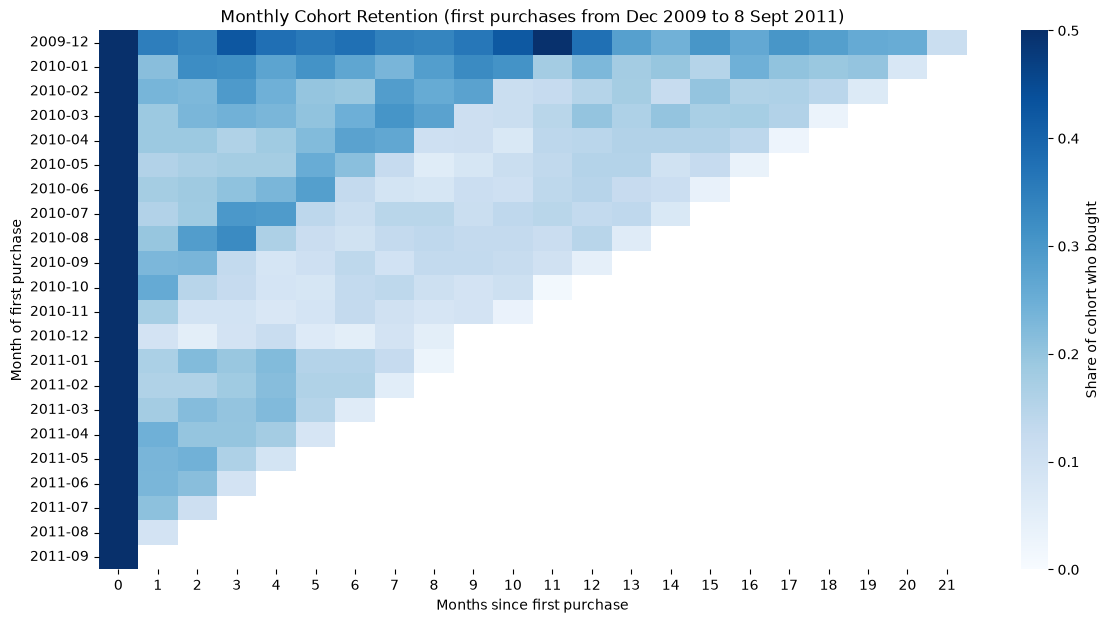

months_since_first,1,2,3
cohort_month,,,
2009-12,0.35,0.33,0.42
2010-01,0.21,0.32,0.32
2010-02,0.23,0.23,0.29
2010-03,0.19,0.23,0.24
2010-04,0.19,0.19,0.16
2010-05,0.16,0.17,0.18
2010-06,0.18,0.19,0.21
2010-07,0.16,0.18,0.30
2010-08,0.20,0.29,0.33


In [70]:
# Only real purchases from the observation window
cohort = obs_hol.loc[obs_hol['transaction_type'] == 'Purchased', ['customer_id', 'invoice_date']].copy()

# Month of each order and month of each customer's first order
cohort['order_month'] = cohort['invoice_date'].dt.to_period('M')
cohort['cohort_month'] = cohort.groupby('customer_id')['order_month'].transform('min')
cohort['months_since_first'] = (cohort['order_month'] - cohort['cohort_month']).apply(lambda x: x.n)

# Number of customers from each cohort who bought in each month after their first
cohort_counts = cohort.groupby(['cohort_month', 'months_since_first'])['customer_id'].nunique().unstack()

# Turning counts into a share of the cohort's starting size
retention = cohort_counts.divide(cohort_counts[0], axis=0)
retention.index = retention.index.astype(str)

plt.figure(figsize=(14, 7))
sns.heatmap(retention, cmap='Blues', vmin=0, vmax=0.5, cbar_kws={'label': 'Share of cohort who bought'})
plt.title('Monthly Cohort Retention (first purchases from Dec 2009 to 8 Sept 2011)')
plt.xlabel('Months since first purchase')
plt.ylabel('Month of first purchase')
plt.show()

retention.iloc[:, 1:4].round(2).head(12)

##### What the cohort heatmap shows

- Month 0 is always 100%, because every customer bought in their first month.
- In month 1, the share drops sharply for every cohort. For most cohorts only about 15–25% of customers bought again the next month.
- The December 2009 cohort (top row) stays darker than the rest across the whole timeline. Many of these customers were already buying before the data starts, so they are older, more settled customers rather than new ones.
- There is a darker diagonal band running across the rows. These are the cells that fall in September to November 2010, whatever month the cohort started. The run-up to Christmas brings customers back to buy.
- The November and December 2010 cohorts are among the lightest rows. Customers who first bought during the Christmas season came back less often than those who started at other times of the year.
- The last cell in each row is lighter because it falls in September 2011, which only has 8 days of data before the cutoff. The 2011-09 row has only month 0 for the same reason.

This fits the buyer type findings. The biggest drop-off happens right after the first purchase.

### Saving the segment table

In [71]:
# Saving the customer table with scores and segments for CRM use and for the churn model
rfm.to_csv("../outputs/customer_segments_holiday.csv", index=False)

print(f"Saved {len(rfm):,} customers to customer_segments_holiday.csv")
print("Columns:", rfm.columns.tolist())

Saved 5,253 customers to customer_segments_holiday.csv
Columns: ['customer_id', 'churn_90d', 'frequency', 'product_breadth', 'monetary', 'recency', 'tenure', 'avg_order_value', 'avg_basket_size', 'cancellation_rate', 'country', 'R', 'F', 'M', 'breadth_score', 'aov_score', 'rfm_code', 'segment', 'total_score', 'recency_band', 'buyer_type']


# Segmentation Summary and Suggested Actions

The segments are built from the customer table as of 9 Sept 2011, using quartile scores for recency, frequency and monetary value. Churn was checked afterwards against the 90 days from 9 Sept to 7 Dec 2011.

| Segment | Customers | Share of revenue | Median spend | Churn rate | Who they are |
|---|---|---|---|---|---|
| Champions | 786 (15.0%) | 59.7% | £4,429 | 16.0% | Buy often, spend the most, bought very recently |
| Loyal | 1,117 (21.3%) | 20.2% | £1,499 | 39.7% | Recent, regular, solid spend |
| Needs Attention | 724 (13.8%) | 2.1% | £343 | 55.8% | Recent but few orders, many are new customers |
| At Risk | 493 (9.4%) | 10.7% | £1,765 | 60.4% | Used to buy often and spend well, now quiet |
| Lapsed | 2,118 (40.4%) | 7.3% | £329 | 79.8% | Bought once or twice, long ago |

### Suggested actions for the CRM team

- **Champions:** Keep them buying. Early access to new stock, account contact for the largest buyers, thank-you messages. Discounts are not needed here, as most of them come back anyway.
- **Loyal:** The aim is to move them up to Champions. Product suggestions based on what they already buy and small rewards for ordering more often. This group has the second highest number of churned customers, so watching their recency is useful.
- **Needs Attention:** Most are new customers with one or two orders. A follow-up series that aims for the second and third order, since churn drops the most after the third order.
- **At Risk:** The best place for win-back spending. They have a high median spend and a high churn rate, and there are only 493 of them, so a personal offer or phone call is affordable.
- **Lapsed:** Low-cost contact only, such as a general seasonal email before Christmas. Most of them bought once, spent little, and have been gone for close to a year.

### Other points

- Contacting customers before they pass about 120 days without an order is likely to work better than waiting. Churn goes above 60% after that point.
- The total score (5 to 20) lines up with churn and can be used to rank customers within a segment. It can also be tested as a feature in the churn model.
- These churn rates come from the holiday window, when many quiet customers return. The At Risk and Lapsed churn rates would likely be higher at other times of the year.

# Exploring the Non-Holiday Customer Features Table for Customer Segmentation Analysis

We now repeat the same segmentation on the non-holiday table (snapshot on 10 Jun 2011). The code and rules are the same as the holiday analysis, so the two sets of segments can be compared.

The holiday analysis used the names `data`, `rfm` and `cutoffs`. The code below reuses these names, so first we keep a copy of the holiday results under their own names.

In [72]:
# Keeping the holiday results under their own names before the same code is reused below
rfm_hol = rfm.copy()
cutoffs_hol = cutoffs.copy()

In [73]:
data = customer_data_nonhol

# Statistical summary
display(data.describe().T)
print("Zero or negative monetary:", (data['monetary'] <= 0).sum())
print("Zero or negative avg order value:", (data['avg_order_value'] <= 0).sum())
print("Zero or negative basket size:", (data['avg_basket_size'] <= 0).sum())
print("Customers who never cancelled:", (data['cancellation_rate'] == 0).sum())
print("Customers who have not bought in over a year:", (data['recency'] > 365).sum())
print("Churn rate:", data['churn_90d'].mean().round(3))
print("Country counts:", data['country'].value_counts().to_dict())

,count,mean,std,min,25%,50%,75%,max
churn_90d,4944.0,0.680016,0.466517,0.00,0.0000,1.000000,1.000000,1.00
frequency,4944.0,5.265372,10.026203,1.00,1.0000,3.000000,6.000000,239.00
product_breadth,4944.0,70.855178,98.205850,1.00,17.0000,40.000000,88.000000,2014.00
monetary,4944.0,2304.716934,10464.632795,-1663.06,307.3075,729.275000,1873.302500,410880.97
recency,4944.0,170.006270,144.975803,0.00,36.0000,145.000000,249.000000,555.00
tenure,4944.0,363.000607,157.135845,0.00,238.0000,399.000000,499.000000,555.00
avg_order_value,4944.0,355.158557,468.477692,-1663.06,170.7775,271.920833,402.840000,11880.84
avg_basket_size,4944.0,239.475377,1433.079945,-1536.00,86.5000,146.000000,249.250000,87167.00
cancellation_rate,4944.0,0.116171,0.168683,0.00,0.0000,0.000000,0.214286,0.80


Zero or negative monetary: 10
Zero or negative avg order value: 10
Zero or negative basket size: 16
Customers who never cancelled: 2941
Customers who have not bought in over a year: 615
Churn rate: 0.68
Country counts: {'UK': 4535, 'non-UK': 409}


In [74]:
# Churned vs retained, median of each feature (churn is not used to build the segments)
display(data.groupby('churn_90d').median(numeric_only=True).T)

churn_90d,0,1
frequency,6.000000,2.000000
product_breadth,79.000000,30.000000
monetary,1914.920000,506.395000
recency,37.000000,204.000000
tenure,442.000000,377.500000
avg_order_value,317.865769,246.547500
avg_basket_size,183.750000,132.566667
cancellation_rate,0.105823,0.000000


In [75]:
# Correlation between features
num_cols = data.select_dtypes('number').columns.drop('churn_90d')
display(data[num_cols].corr().round(2))

,frequency,product_breadth,monetary,recency,tenure,avg_order_value,avg_basket_size,cancellation_rate
frequency,1.00,0.69,0.63,-0.30,0.31,0.09,0.01,0.09
product_breadth,0.69,1.00,0.42,-0.32,0.31,0.16,0.02,0.12
monetary,0.63,0.42,1.00,-0.15,0.15,0.33,0.09,0.04
recency,-0.30,-0.32,-0.15,1.00,0.22,-0.05,0.01,-0.09
tenure,0.31,0.31,0.15,0.22,1.00,0.02,0.00,0.13
avg_order_value,0.09,0.16,0.33,-0.05,0.02,1.00,0.57,0.08
avg_basket_size,0.01,0.02,0.09,0.01,0.00,0.57,1.00,0.01
cancellation_rate,0.09,0.12,0.04,-0.09,0.13,0.08,0.01,1.00


In [76]:
# Spearman correlation works on ranks, so it is less affected by the skew
display(data[num_cols].corr(method='spearman').round(2))

,frequency,product_breadth,monetary,recency,tenure,avg_order_value,avg_basket_size,cancellation_rate
frequency,1.00,0.70,0.84,-0.56,0.55,0.19,0.17,0.37
product_breadth,0.70,1.00,0.77,-0.42,0.38,0.43,0.41,0.30
monetary,0.84,0.77,1.00,-0.50,0.46,0.66,0.56,0.38
recency,-0.56,-0.42,-0.50,1.00,0.10,-0.17,-0.15,-0.20
tenure,0.55,0.38,0.46,0.10,1.00,0.09,0.08,0.23
avg_order_value,0.19,0.43,0.66,-0.17,0.09,1.00,0.83,0.20
avg_basket_size,0.17,0.41,0.56,-0.15,0.08,0.83,1.00,0.16
cancellation_rate,0.37,0.30,0.38,-0.20,0.23,0.20,0.16,1.00


##### What the non-holiday features table shows

This table is a snapshot of each customer as of 10 Jun 2011. Churn is checked over the 90 days after it (10 Jun to 7 Sept 2011).

**Size and churn rate**

The table has 4,944 customers, and 68.0% of them churned. This is higher than the 56.6% in the holiday table, which matches the McNemar test: fewer customers come back in the summer months than before Christmas.

**How the features are spread**

- The features are skewed in the same way as the holiday table. The median customer spent £729, the average is £2,305, and the top customer spent £410,881.
- At least a quarter of customers bought only once, and the median is 3 orders.
- A quarter of customers bought in the last 36 days, and another quarter have not bought in over 249 days. 615 customers have not bought in over a year. These numbers are lower than in the holiday table because the data before this cutoff is about three months shorter.
- Tenure tops out at 555 days, which is the full length of the data before this cutoff.
- 2,941 customers (59.5%) never cancelled, almost the same share as the holiday table.
- 10 customers have zero or negative spend and 16 have a zero or negative basket size. As in the holiday analysis, they are kept in the table. They get the lowest M score, so they end up in the low-value segments.
- Country: 4,535 UK and 409 non-UK customers.

**Churned vs retained customers (medians, background only)**

- Recency again shows the biggest gap. Retained customers last bought 37 days before the cutoff, churned customers 204 days before.
- Retained customers placed 6 orders compared to 2, bought 79 different products compared to 30, and spent almost four times as much (£1,915 vs £506).
- Order value (£318 vs £247) and basket size (184 vs 133 items) differ less.
- Tenure is a little higher for retained customers (442 vs 378 days).
- Retained customers cancel more (median 11% vs 0%), for the same reason as before: more orders mean more chances to cancel.

**Correlation between features**

The correlations are almost the same as in the holiday table. With Spearman, frequency and monetary are at 0.84, average order value and basket size at 0.83, and frequency and product breadth at 0.70. Since the scoring reads each feature on its own, these pairs don't need to be removed.

### Customer Segmentation with RFM Scoring (Non-Holiday)

The same five features are scored from 1 to 4 using quartiles, and the same rules turn the R, F and M scores into segments. The only difference is that the quartile cut-offs are worked out from the non-holiday table.

In [77]:
# Working on a copy of the non-holiday customer table
rfm = data.copy()

# Quartile cut-offs (25th, 50th and 75th percentile) for each feature we score
score_cols = ['recency', 'frequency', 'monetary', 'product_breadth', 'avg_order_value']
cutoffs = rfm[score_cols].quantile([0.25, 0.50, 0.75])

cutoffs

,recency,frequency,monetary,product_breadth,avg_order_value
0.25,36.0,1.0,307.3075,17.0,170.777500
0.50,145.0,3.0,729.2750,40.0,271.920833
0.75,249.0,6.0,1873.3025,88.0,402.840000


##### What the cut-offs mean

For recency, a quarter of customers bought in the last 36 days, half in the last 145 days, and a quarter have not bought in more than 249 days. These are shorter than the holiday cut-offs (49, 162 and 324 days).

The frequency cut-offs are the same as the holiday table: one order, two to three orders, four to six orders, or seven or more. Monetary, breadth and order value cut-offs are close to the holiday ones.

In [78]:
# Giving each customer a 1-4 score on every feature
# (high_is_good and low_is_good are the same functions as before, they now read the non-holiday cut-offs)
rfm['R'] = rfm['recency'].apply(low_is_good, args=('recency',))
rfm['F'] = rfm['frequency'].apply(high_is_good, args=('frequency',))
rfm['M'] = rfm['monetary'].apply(high_is_good, args=('monetary',))
rfm['breadth_score'] = rfm['product_breadth'].apply(high_is_good, args=('product_breadth',))
rfm['aov_score'] = rfm['avg_order_value'].apply(high_is_good, args=('avg_order_value',))

# How many customers got each score
score_counts = rfm[['R', 'F', 'M', 'breadth_score', 'aov_score']].apply(pd.Series.value_counts)
score_counts.index.name = 'score'
score_counts

,R,F,M,breadth_score,aov_score
score,,,,,
1,1218,1545,1236,1242,1236
2,1254,1403,1236,1244,1236
3,1222,930,1236,1237,1236
4,1250,1066,1236,1221,1236


Every score except F splits customers into four groups of roughly 1,200 to 1,250 each. F is uneven again: 1,545 one-time buyers all get an F score of 1.

### Building the segments

The segments use the same `assign_segment` rules as the holiday table (see the rule table above). We also add up all five scores into a total score from 5 to 20.

In [79]:
# The 3-digit RFM code
rfm['rfm_code'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

# Same segment rules as the holiday table (assign_segment defined earlier)
rfm['segment'] = rfm.apply(assign_segment, axis=1)

# Total score from all five scores (5 to 20)
rfm['total_score'] = rfm['R'] + rfm['F'] + rfm['M'] + rfm['breadth_score'] + rfm['aov_score']

rfm[['customer_id', 'recency', 'frequency', 'monetary', 'rfm_code', 'segment', 'total_score']].head(10)

,customer_id,recency,frequency,monetary,rfm_code,segment,total_score
0,13085,112,7,2151.60,344,Loyal,17
1,13078,17,41,20281.27,444,Champions,20
2,15362,265,2,613.08,122,Lapsed,10
3,18102,0,102,410880.97,444,Champions,20
4,12682,9,31,14347.59,444,Champions,20
5,18087,107,16,13808.42,344,Loyal,18
6,13635,259,3,1877.19,124,At Risk,15
7,14110,37,23,8977.97,344,Loyal,18
8,17519,23,12,3880.80,444,Champions,19
9,13758,18,12,7705.26,444,Champions,20


In [80]:
# How many customers are in each segment
segment_sizes = pd.DataFrame({
    'customers': rfm['segment'].value_counts(),
    'share_%': (rfm['segment'].value_counts(normalize=True) * 100).round(1)
}).reindex(segment_order)

segment_sizes

,customers,share_%
segment,,
Champions,715,14.5
Loyal,1014,20.5
Needs Attention,743,15.0
At Risk,458,9.3
Lapsed,2014,40.7


##### Segment sizes

Lapsed is again the biggest group, with 2,014 customers (40.7%). Loyal is next at 1,014 (20.5%), then Needs Attention at 743 (15.0%), Champions at 715 (14.5%), and At Risk at 458 (9.3%).

The shares are very close to the holiday table. This is expected, since the scores are based on quartiles, so the segment sizes depend more on the rules than on the season.

### Describing each segment

In [81]:
# Median of each feature per segment
segment_profile = rfm.groupby('segment')[['recency', 'frequency', 'monetary', 'product_breadth',
                                          'avg_order_value', 'avg_basket_size', 'tenure', 'total_score']].median()

segment_profile = segment_profile.reindex(segment_order).round(1)
segment_profile

,recency,frequency,monetary,product_breadth,avg_order_value,avg_basket_size,tenure,total_score
segment,,,,,,,,
Champions,16.0,11.0,4109.4,135.0,360.8,208.6,504.0,19.0
Loyal,61.0,5.0,1512.2,72.0,310.4,175.9,441.0,16.0
Needs Attention,63.0,1.0,321.1,20.0,206.2,106.0,101.0,10.0
At Risk,210.0,5.0,1755.1,72.5,309.4,170.6,490.5,14.0
Lapsed,262.0,1.0,336.8,23.0,224.8,125.8,367.0,9.0


##### What the segment profile shows

- **Champions** last bought 16 days before the cutoff, placed 11 orders, spent £4,109, and bought 135 different products. They have the highest order value (£361) and basket size (209 items).
- **Loyal** customers are recent (61 days) with 5 orders and £1,512 spent.
- **Needs Attention** customers are recent (63 days) but the median customer has only 1 order and £321 spent. Their tenure is 101 days, the shortest of any group. Many are new customers.
- **At Risk** customers placed 5 orders and spent £1,755, more than the Loyal group, but last bought 210 days before the cutoff.
- **Lapsed** customers last bought 262 days before the cutoff, placed 1 order and spent £337.

The profiles look much like the holiday ones. The main difference is that At Risk and Lapsed customers have shorter recency (210 and 262 days, against 284 and 336 in the holiday table), because the data before this cutoff is shorter.

### Customer value by segment

In [82]:
# Historical spend per segment
segment_value = rfm.groupby('segment')['monetary'].agg(
    customers='count',
    mean_spend='mean',
    median_spend='median',
    total_spend='sum'
).reindex(segment_order)

segment_value['share_of_customers_%'] = (segment_value['customers'] / segment_value['customers'].sum() * 100)
segment_value['share_of_revenue_%'] = (segment_value['total_spend'] / segment_value['total_spend'].sum() * 100)

segment_value.round(1)

,customers,mean_spend,median_spend,total_spend,share_of_customers_%,share_of_revenue_%
segment,,,,,,
Champions,715,9253.4,4109.4,6616154.7,14.5,58.1
Loyal,1014,2334.3,1512.2,2366959.0,20.5,20.8
Needs Attention,743,373.9,321.1,277821.9,15.0,2.4
At Risk,458,2625.1,1755.1,1202278.8,9.3,10.6
Lapsed,2014,462.4,336.8,931306.2,40.7,8.2


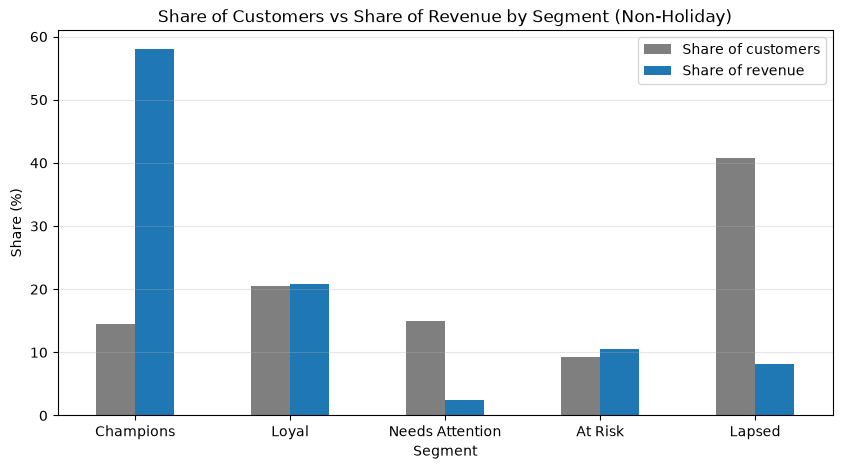

In [83]:
# Share of customers vs share of revenue for each segment
share_table = segment_value[['share_of_customers_%', 'share_of_revenue_%']]

share_table.plot(kind='bar', figsize=(10, 5), color=['tab:gray', 'tab:blue'])
plt.title('Share of Customers vs Share of Revenue by Segment (Non-Holiday)')
plt.xlabel('Segment')
plt.ylabel('Share (%)')
plt.xticks(rotation=0)
plt.legend(['Share of customers', 'Share of revenue'])
plt.grid(axis='y', alpha=0.3)
plt.show()

##### What the value table and chart show

- **Champions** are 14.5% of customers but brought in 58.1% of revenue up to the cutoff. The median Champion spent £4,109, while the mean is £9,253, so a few very large buyers sit in this group.
- **Loyal** customers are 20.5% of customers and 20.8% of revenue.
- **At Risk** customers are 9.3% of customers and 10.6% of revenue. Their median spend (£1,755) is again higher than Loyal (£1,512).
- **Needs Attention** and **Lapsed** together are 55.7% of customers but only 10.6% of revenue.

Champions and Loyal together bring in about 79% of the revenue, almost the same as the holiday table (80%).

### Churn rate by segment

Now we check the segments against what happened in the 90 days after the cutoff (10 Jun to 7 Sept 2011).

segment
Champions          22.8
Loyal              51.4
Needs Attention    72.1
At Risk            75.5
Lapsed             89.2
Name: churn_90d, dtype: float64
Overall churn rate: 68.0%


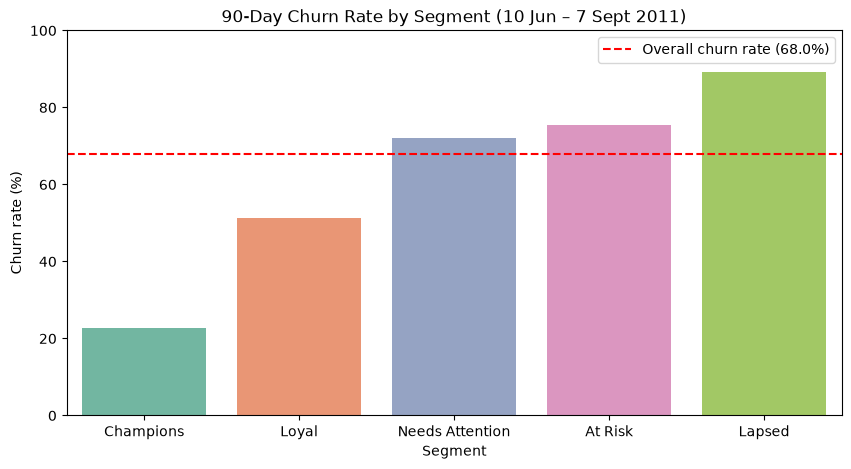

In [84]:
# Churn rate in each segment
churn_by_segment = (rfm.groupby('segment')['churn_90d'].mean() * 100).reindex(segment_order)
overall_churn = rfm['churn_90d'].mean() * 100

print(churn_by_segment.round(1))
print(f"Overall churn rate: {overall_churn:.1f}%")

plt.figure(figsize=(10, 5))
sns.barplot(x=churn_by_segment.index, y=churn_by_segment.values,
            hue=churn_by_segment.index, palette='Set2', legend=False)
plt.axhline(overall_churn, color='red', linestyle='--', label=f'Overall churn rate ({overall_churn:.1f}%)')
plt.title('90-Day Churn Rate by Segment (10 Jun – 7 Sept 2011)')
plt.xlabel('Segment')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.show()

##### What the churn rate chart shows

The churn rate goes up step by step from Champions to Lapsed, the same order as the holiday table:

- **Champions:** 22.8%. More than 3 in 4 bought again in the next 90 days.
- **Loyal:** 51.4%, well below the overall rate of 68.0%. About half of them came back.
- **Needs Attention:** 72.1%, a little above the overall rate.
- **At Risk:** 75.5%. Only about 1 in 4 came back.
- **Lapsed:** 89.2%. Only about 1 in 10 came back.

Every segment has a higher churn rate than in the holiday window. In the summer months fewer customers place an order, so the same kind of customer is more likely to count as churned.

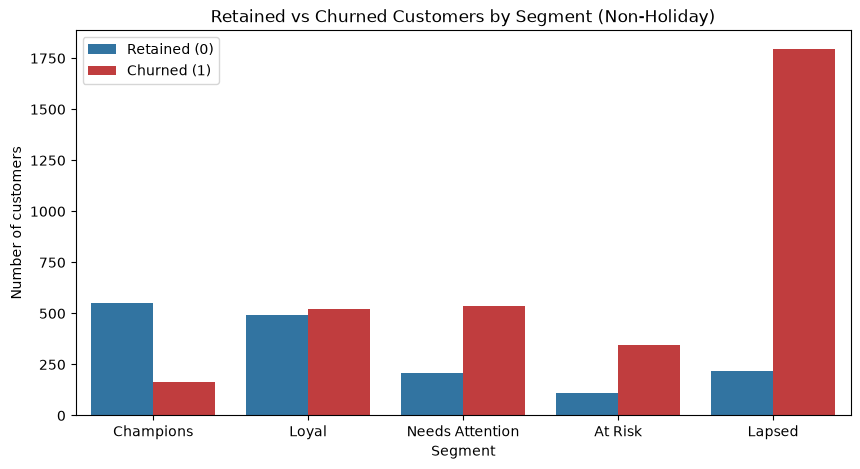

churn_90d,0,1
segment,,
Champions,552,163
Loyal,493,521
Needs Attention,207,536
At Risk,112,346
Lapsed,218,1796


In [85]:
# Number of churned and retained customers in each segment
plt.figure(figsize=(10, 5))
sns.countplot(data=rfm, x='segment', hue='churn_90d', order=segment_order,
              palette={0: 'tab:blue', 1: 'tab:red'})
plt.title('Retained vs Churned Customers by Segment (Non-Holiday)')
plt.xlabel('Segment')
plt.ylabel('Number of customers')
plt.legend(title='', labels=['Retained (0)', 'Churned (1)'])
plt.show()

pd.crosstab(rfm['segment'], rfm['churn_90d']).reindex(segment_order)

##### What the churn count chart shows

- **Lapsed** has 1,796 churned customers, more than every other segment put together (1,566).
- **Loyal** is split almost in half: 493 retained and 521 churned. In the holiday table far more Loyal customers were retained (676 vs 444).
- **At Risk** has 346 churned and only 112 retained.
- **Champions** is the only group where retained customers (552) are far more than churned ones (163).

### Does the total score line up with churn?

             customers  churn_rate
total_score                       
5                  228        95.6
6                  289        95.2
7                  316        91.8
8                  297        90.9
9                  348        81.9
10                 390        81.0
11                 377        76.4
12                 349        73.4
13                 355        74.9
14                 357        68.9
15                 305        63.6
16                 280        55.7
17                 264        42.4
18                 324        29.0
19                 275        24.4
20                 190        15.3


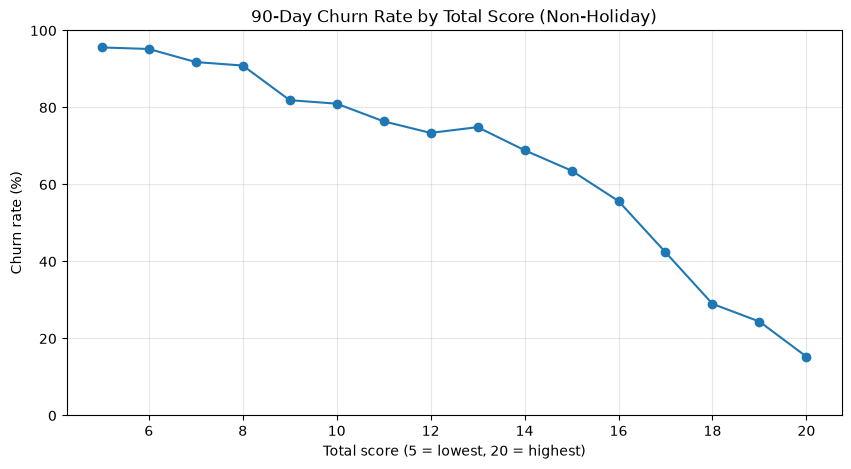

In [86]:
# Churn rate for each total score
score_churn = rfm.groupby('total_score')['churn_90d'].agg(customers='size', churn_rate='mean')
score_churn['churn_rate'] = (score_churn['churn_rate'] * 100).round(1)
print(score_churn)

plt.figure(figsize=(10, 5))
plt.plot(score_churn.index, score_churn['churn_rate'], marker='o')
plt.title('90-Day Churn Rate by Total Score (Non-Holiday)')
plt.xlabel('Total score (5 = lowest, 20 = highest)')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

##### What the total score chart shows

Churn falls as the total score goes up. Customers with a score of 5 churned 95.6% of the time, and those with a score of 20 churned 15.3% of the time. There are a few flat steps (5 and 6, 7 and 8, 9 and 10, 12 and 13), but the overall direction is clear, as in the holiday table.

At every score level churn is higher than in the holiday window. The score ranks customers in the same order in both seasons, but the level of churn depends on the time of year.

### Churn by days since last purchase

              customers  churn_rate
recency_band                       
0-30               1069        37.4
31-60               513        46.0
61-90               402        62.2
91-120              301        67.4
121-180             352        69.9
181-270            1265        84.7
271-365             427        88.1
365+                615        94.3


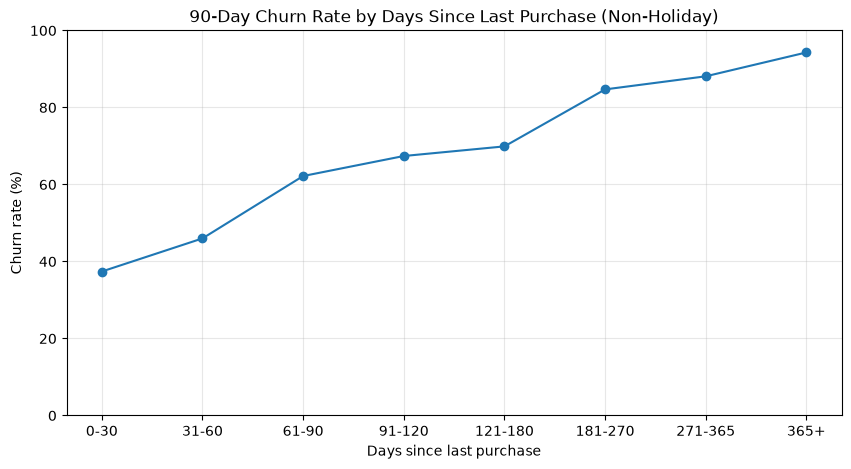

In [87]:
# Splitting recency into bands
recency_bins = [0, 30, 60, 90, 120, 180, 270, 365, rfm['recency'].max() + 1]
recency_labels = ['0-30', '31-60', '61-90', '91-120', '121-180', '181-270', '271-365', '365+']

rfm['recency_band'] = pd.cut(rfm['recency'], bins=recency_bins, labels=recency_labels, include_lowest=True)

recency_churn = rfm.groupby('recency_band', observed=True)['churn_90d'].agg(customers='size', churn_rate='mean')
recency_churn['churn_rate'] = (recency_churn['churn_rate'] * 100).round(1)
print(recency_churn)

plt.figure(figsize=(10, 5))
plt.plot(recency_churn.index.astype(str), recency_churn['churn_rate'], marker='o')
plt.title('90-Day Churn Rate by Days Since Last Purchase (Non-Holiday)')
plt.xlabel('Days since last purchase')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

##### What the recency chart shows

- Customers who bought in the last 30 days have the lowest churn rate, 37.4%.
- Churn goes up to 46.0% at 31–60 days, then jumps to 62.2% at 61–90 days. In the summer window, the point where a customer becomes more likely to churn than return comes earlier, at around 60 days (against about 120 days in the holiday window).
- At 181–270 days churn is 84.7%, and after a year it is 94.3%.

The 181–270 day band holds the most customers (1,265). Together with the bands above it, 2,307 customers had not bought for more than 6 months.

For the shop, this suggests that in ordinary months, contact should start before customers reach about 60 days without an order.

### One-time, two-time and repeat buyers

About 31% of customers bought only once.

                    customers  churn_rate  median_spend
buyer_type                                             
One-time buyers          1545        88.3        234.75
Two-time buyers           856        80.4        493.62
Repeat buyers (3+)       2543        51.5       1739.53


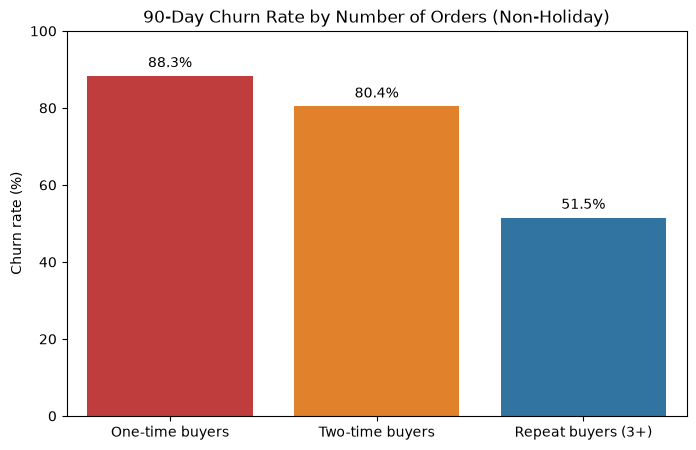

In [88]:
# Grouping customers by how many orders they have placed (buyer_type defined earlier)
rfm['buyer_type'] = rfm['frequency'].apply(buyer_type)

buyer_summary = rfm.groupby('buyer_type').agg(
    customers=('churn_90d', 'size'),
    churn_rate=('churn_90d', 'mean'),
    median_spend=('monetary', 'median')
).reindex(buyer_order)
buyer_summary['churn_rate'] = (buyer_summary['churn_rate'] * 100).round(1)
print(buyer_summary)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=buyer_summary.index, y=buyer_summary['churn_rate'],
                 hue=buyer_summary.index, palette=['tab:red', 'tab:orange', 'tab:blue'], legend=False)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height()}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points')
plt.title('90-Day Churn Rate by Number of Orders (Non-Holiday)')
plt.xlabel('')
plt.ylabel('Churn rate (%)')
plt.ylim(0, 100)
plt.show()

##### What the buyer type chart shows

- **One-time buyers** (1,545 customers) churned 88.3% of the time and have a median spend of £235.
- **Two-time buyers** (856) churned 80.4% of the time, with a median spend of £494.
- **Repeat buyers** with 3 or more orders (2,543) churned 51.5% of the time, with a median spend of £1,740.

The second order lowers churn by about 8 percentage points, and the third order lowers it by another 29. As in the holiday table, the larger change comes at the third order.

In [89]:
# How the buyer types are spread across the segments
pd.crosstab(rfm['segment'], rfm['buyer_type']).reindex(index=segment_order, columns=buyer_order)

buyer_type,One-time buyers,Two-time buyers,Repeat buyers (3+)
segment,,,
Champions,0,0,715
Loyal,1,82,931
Needs Attention,401,225,117
At Risk,0,23,435
Lapsed,1143,526,345


Champions are all repeat buyers, and nearly all Loyal and At Risk customers are too. Lapsed is mostly one-time buyers (1,143 of 2,014). Needs Attention has 401 one-time and 225 two-time buyers out of 743, which matches its short tenure.

### Average order value by segment

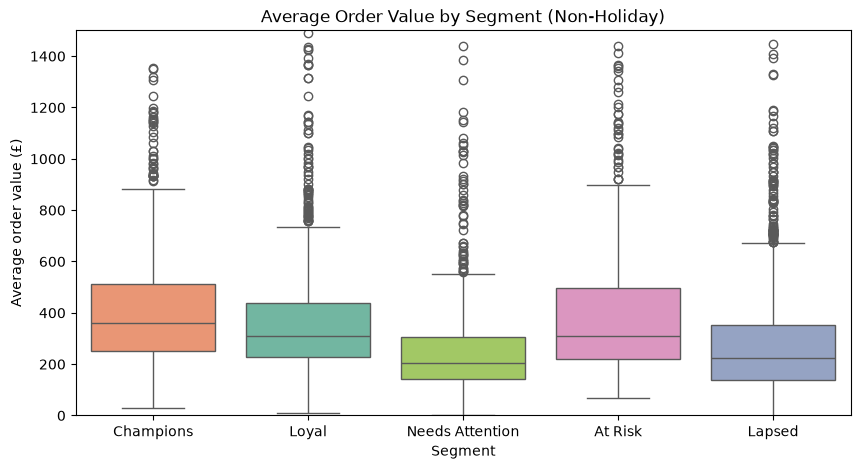

,count,mean,std,min,25%,50%,75%,max
segment,,,,,,,,
Champions,715.0,472.1,500.8,29.9,252.3,360.8,513.7,6940.9
Loyal,1014.0,393.0,446.8,11.3,226.5,310.4,436.8,9330.5
Needs Attention,743.0,262.6,219.4,-200.8,140.4,206.2,305.5,1829.0
At Risk,458.0,466.2,511.7,67.9,220.6,309.4,497.8,6075.1
Lapsed,2014.0,303.5,508.0,-1663.1,139.1,224.8,352.6,11880.8


In [90]:
# Average order value by segment
plt.figure(figsize=(10, 5))
sns.boxplot(data=rfm, x='segment', y='avg_order_value', order=segment_order,
            hue='segment', palette='Set2', legend=False)
plt.ylim(0, 1500)   # capping the axis so the boxes are readable
plt.title('Average Order Value by Segment (Non-Holiday)')
plt.xlabel('Segment')
plt.ylabel('Average order value (£)')
plt.show()

rfm.groupby('segment')['avg_order_value'].describe().reindex(segment_order).round(1)

##### What the order value chart shows

- **Champions** have the highest typical order value (median £361), with the middle half between about £252 and £514.
- **Loyal** (£310) and **At Risk** (£309) are almost the same, as in the holiday table.
- **Needs Attention** (£206) and **Lapsed** (£225) have the lowest order values.
- The negative minimum values in Needs Attention and Lapsed come from the customers with zero or negative spend that were kept in the table.

Every segment has a long tail of high values, reaching up to £11,881 per order in Lapsed.

### Country and cancellations by segment

In [91]:
# Share of non-UK customers and cancellation behaviour in each segment
extra_profile = rfm.groupby('segment').agg(
    non_uk_share=('country', lambda s: (s == 'non-UK').mean() * 100),
    ever_cancelled_share=('cancellation_rate', lambda s: (s > 0).mean() * 100),
    median_cancellation_rate=('cancellation_rate', 'median')
).reindex(segment_order).round(2)

extra_profile

,non_uk_share,ever_cancelled_share,median_cancellation_rate
segment,,,
Champions,8.81,80.14,0.15
Loyal,10.16,57.59,0.14
Needs Attention,9.15,18.98,0.00
At Risk,6.55,56.99,0.14
Lapsed,7.20,22.05,0.00


##### What the country and cancellation table shows

- **Country:** Non-UK customers make up between 6.6% and 10.2% of each segment, so country does not change much between groups.
- **Cancellations:** 80.1% of Champions have cancelled at least once, compared with 19.0% of Needs Attention and 22.1% of Lapsed. Loyal and At Risk are at about 57–58%. As before, this follows the number of orders placed.

### Monthly cohort retention

This uses only purchases from the non-holiday observation window (1 Dec 2009 to 9 Jun 2011).

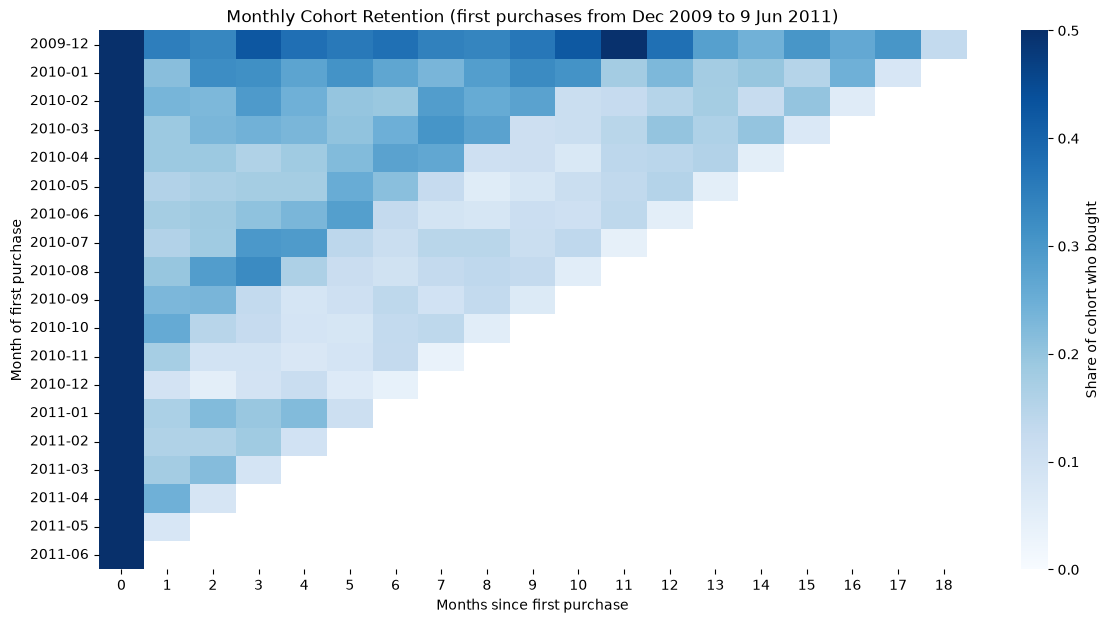

months_since_first,1,2,3
cohort_month,,,
2009-12,0.35,0.33,0.42
2010-01,0.21,0.32,0.32
2010-02,0.23,0.23,0.29
2010-03,0.19,0.23,0.24
2010-04,0.19,0.19,0.16
2010-05,0.16,0.17,0.18
2010-06,0.18,0.19,0.21
2010-07,0.16,0.18,0.30
2010-08,0.20,0.29,0.33


In [92]:
# Only real purchases from the non-holiday observation window
cohort = obs_nonhol.loc[obs_nonhol['transaction_type'] == 'Purchased', ['customer_id', 'invoice_date']].copy()

# Month of each order and month of each customer's first order
cohort['order_month'] = cohort['invoice_date'].dt.to_period('M')
cohort['cohort_month'] = cohort.groupby('customer_id')['order_month'].transform('min')
cohort['months_since_first'] = (cohort['order_month'] - cohort['cohort_month']).apply(lambda x: x.n)

# Number of customers from each cohort who bought in each month after their first
cohort_counts = cohort.groupby(['cohort_month', 'months_since_first'])['customer_id'].nunique().unstack()

# Turning counts into a share of the cohort's starting size
retention = cohort_counts.divide(cohort_counts[0], axis=0)
retention.index = retention.index.astype(str)

plt.figure(figsize=(14, 7))
sns.heatmap(retention, cmap='Blues', vmin=0, vmax=0.5, cbar_kws={'label': 'Share of cohort who bought'})
plt.title('Monthly Cohort Retention (first purchases from Dec 2009 to 9 Jun 2011)')
plt.xlabel('Months since first purchase')
plt.ylabel('Month of first purchase')
plt.show()

retention.iloc[:, 1:4].round(2).head(12)

##### What the cohort heatmap shows

- The pattern is the same as in the holiday heatmap, since both use the same data up to June 2011.
- In month 1, the share drops sharply for every cohort, to about 15–25% for most cohorts.
- The December 2009 cohort stays darker than the rest across the whole timeline.
- The darker diagonal band in the cells that fall in September to November 2010 shows the Christmas season bringing customers back.
- The November and December 2010 cohorts are among the lightest rows.
- The last cell in each row is lighter because it falls in June 2011, which has only 9 days of data before the cutoff. The 2011-06 row has only month 0 for the same reason.

### Saving the non-holiday segment table

In [93]:
# Saving the non-holiday customer table with scores and segments
rfm.to_csv("../outputs/customer_segments_nonholiday.csv", index=False)

# Keeping the non-holiday results under their own name
rfm_nonhol = rfm.copy()

print(f"Saved {len(rfm):,} customers to customer_segments_nonholiday.csv")
print("Columns:", rfm.columns.tolist())

Saved 4,944 customers to customer_segments_nonholiday.csv
Columns: ['customer_id', 'churn_90d', 'frequency', 'product_breadth', 'monetary', 'recency', 'tenure', 'avg_order_value', 'avg_basket_size', 'cancellation_rate', 'country', 'R', 'F', 'M', 'breadth_score', 'aov_score', 'rfm_code', 'segment', 'total_score', 'recency_band', 'buyer_type']


# Comparing the Non-Holiday and Holiday Segments

Both tables use the same scoring and rules, so we can put them side by side.

                 share_nonhol_%  share_hol_%  churn_nonhol_%  churn_hol_%
segment                                                                  
Champions                  14.5         15.0            22.8         16.0
Loyal                      20.5         21.3            51.4         39.6
Needs Attention            15.0         13.7            72.1         56.0
At Risk                     9.3          9.4            75.5         60.4
Lapsed                     40.7         40.5            89.2         79.9


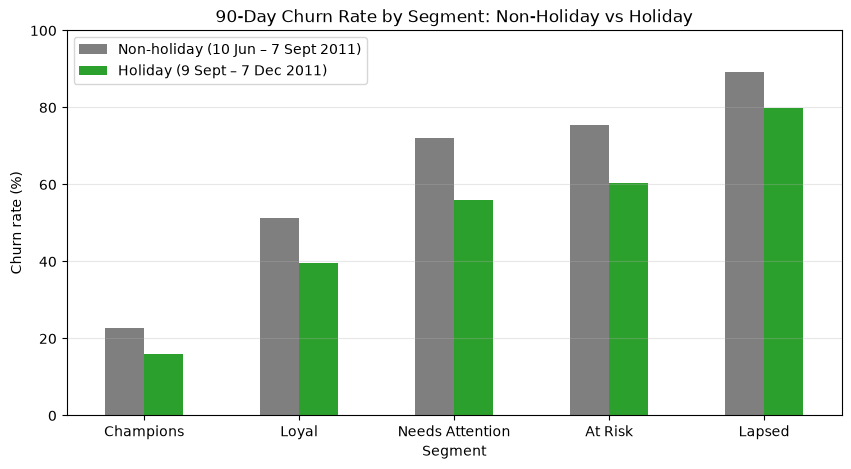

In [94]:
# Segment share and churn rate in each season, side by side
compare = pd.DataFrame({
    'share_nonhol_%': rfm_nonhol['segment'].value_counts(normalize=True) * 100,
    'share_hol_%': rfm_hol['segment'].value_counts(normalize=True) * 100,
    'churn_nonhol_%': rfm_nonhol.groupby('segment')['churn_90d'].mean() * 100,
    'churn_hol_%': rfm_hol.groupby('segment')['churn_90d'].mean() * 100,
}).reindex(segment_order).round(1)

print(compare)

compare[['churn_nonhol_%', 'churn_hol_%']].plot(kind='bar', figsize=(10, 5), color=['tab:gray', 'tab:green'])
plt.title('90-Day Churn Rate by Segment: Non-Holiday vs Holiday')
plt.xlabel('Segment')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(['Non-holiday (10 Jun – 7 Sept 2011)', 'Holiday (9 Sept – 7 Dec 2011)'])
plt.grid(axis='y', alpha=0.3)
plt.show()

##### What the comparison shows

- **Segment sizes** are almost the same in both seasons (within about 1.5 percentage points), because the scores are based on quartiles.
- **Churn is higher in every segment in the non-holiday window.** The gap is largest for Needs Attention (72.1% vs 56.0%) and At Risk (75.5% vs 60.4%), about 15–16 percentage points. It is about 12 points for Loyal, 9 for Lapsed and 7 for Champions.
- So the Christmas season brings back more of the customers in the middle and lower segments. Champions come back in both seasons.
- The order of the segments does not change. Champions churn the least and Lapsed the most in both windows, so the same rules work in both seasons.

### How customers moved between segments from June to September

All 4,944 customers in the non-holiday table are also in the holiday table. This shows which segment each of them was in on 10 Jun 2011 and on 9 Sept 2011.

In [95]:
# Customers who appear in both tables: segment in June vs segment in September
moves = rfm_nonhol[['customer_id', 'segment']].merge(
    rfm_hol[['customer_id', 'segment']], on='customer_id', suffixes=('_nonhol', '_hol'))

movement = pd.crosstab(moves['segment_nonhol'], moves['segment_hol'])
movement = movement.reindex(index=segment_order, columns=segment_order)
movement.index.name = 'Segment on 10 Jun 2011'
movement.columns.name = 'Segment on 9 Sept 2011'

print(f"Customers in both tables: {len(moves):,}")
movement

Customers in both tables: 4,944


Segment on 9 Sept 2011,Champions,Loyal,Needs Attention,At Risk,Lapsed
Segment on 10 Jun 2011,,,,,
Champions,468,247,0,0,0
Loyal,252,533,2,155,72
Needs Attention,7,113,364,0,259
At Risk,48,65,0,340,5
Lapsed,9,128,83,0,1794


In [96]:
# Same table as a share of each June segment (each row adds up to 100%)
(movement.div(movement.sum(axis=1), axis=0) * 100).round(1)

Segment on 9 Sept 2011,Champions,Loyal,Needs Attention,At Risk,Lapsed
Segment on 10 Jun 2011,,,,,
Champions,65.5,34.5,0.0,0.0,0.0
Loyal,24.9,52.6,0.2,15.3,7.1
Needs Attention,0.9,15.2,49.0,0.0,34.9
At Risk,10.5,14.2,0.0,74.2,1.1
Lapsed,0.4,6.4,4.1,0.0,89.1


##### What the movement tables show

Each row shows where the customers from one June segment were three months later.

- **Champions:** 65.5% were still Champions in September and 34.5% moved to Loyal. None dropped to At Risk or Lapsed.
- **Loyal:** 52.6% stayed Loyal and 24.9% moved up to Champions. But 15.3% moved to At Risk and 7.1% to Lapsed. These are the customers who stopped buying over the summer.
- **Needs Attention:** 49.0% stayed and 15.2% moved up to Loyal, but 34.9% became Lapsed. Many new customers did not place another order over the summer.
- **At Risk:** 74.2% were still At Risk. 24.7% moved up to Champions or Loyal, which means they started buying again.
- **Lapsed:** 89.1% were still Lapsed. Only a small share moved up.

So over the summer, the two groups that most need watching are Loyal (about 1 in 5 slipped to At Risk or Lapsed) and Needs Attention (about 1 in 3 became Lapsed).

# Non-Holiday Segmentation Summary and Suggested Actions

The segments are built from the customer table as of 10 Jun 2011. Churn was checked against the 90 days from 10 Jun to 7 Sept 2011.

| Segment | Customers | Share of revenue | Median spend | Churn rate (non-holiday) | Churn rate (holiday) |
|---|---|---|---|---|---|
| Champions | 715 (14.5%) | 58.1% | £4,109 | 22.8% | 16.0% |
| Loyal | 1,014 (20.5%) | 20.8% | £1,512 | 51.4% | 39.6% |
| Needs Attention | 743 (15.0%) | 2.4% | £321 | 72.1% | 56.0% |
| At Risk | 458 (9.3%) | 10.6% | £1,755 | 75.5% | 60.4% |
| Lapsed | 2,014 (40.7%) | 8.2% | £337 | 89.2% | 79.9% |

### Suggested actions for the CRM team in ordinary months

- **Champions:** Same as in the holiday season. Keep them buying with early access to new stock and account contact for the largest buyers. About 1 in 3 moved down to Loyal over the summer, so a regular check-in helps.
- **Loyal:** The main group to protect in the summer. Half of them churned, and about 1 in 5 slipped to At Risk or Lapsed by September. Reminders and product suggestions once they pass about 60 days without an order.
- **Needs Attention:** A follow-up series aiming for the second and third order. About a third of them became Lapsed by September, so the follow-up should start soon after the first purchase.
- **At Risk:** Still the best place for win-back spending, but expect fewer to return in the summer (about 1 in 4) than before Christmas. It may be better to plan the main win-back offer for September and October, when these customers are more likely to buy anyway.
- **Lapsed:** Low-cost contact only. About 9 in 10 did not buy in the summer window.

### Other points

- In ordinary months, the point where churn goes above 60% comes at around 60 days without an order, earlier than the 120 days seen in the holiday window.
- The segments and the total score rank customers in the same order in both seasons, but churn is higher in every segment in the summer. This supports building separate models for the two seasons.